# SymVeR — final algorithm

Definition, validation on synthetic data, application to EMA and SMEAR, hysteresis plots

**Part A** defines the method. **Part B** validates it on synthetic systems with known ground truth. **Part C** applies it to the EMA and SMEAR datasets. **Part D** draws the hysteresis plot of every *driver → response* pair identified by SymVeR.

Run the cells in order (Shift+Enter). Requirements: numpy, pandas, scipy, matplotlib.
Data files for Part C (`ESMdata.csv`, `New_24HourDataset_SMEAR.csv`) must be in the notebook folder; each Part C cell is skipped if its file is missing.

Approximate run time: Part A < 1 s, Part B ≈ 25-30 min (≈ 4 min with `QUICK = True`), Part C ≈ 3-5 min, Part D < 1 min.

## Procedure

```
input: a(t), b(t)
├─ DCRP → τ   (diagonal cross-recurrence profile of the ternarized series)
│   ├─ τ ≠ 0 → lag-asymmetry test (circular-shift surrogates)
│   │           not significant → no coupling
│   │           significant     → candidate driver = the leading variable (a if τ > 0, b if τ < 0)
│   └─ τ = 0 → synchrony test on RR(0) (circular-shift surrogates)
│               not significant → no coupling
│               significant     → synchronous coupling
├─ Trapping time (raw series) and laminarity (ternarized series), block-bootstrap tests
│   ├─ τ ≠ 0: the candidate has higher TT and higher Lam → "driver → response, delay τ"
│   ├─ τ = 0: one variable has higher TT and higher Lam → "slow (effective parameter) ↔ fast, synchronous"
│   └─ otherwise → "coupled, no timescale hierarchy"
```

Multiple comparisons are handled in two stages with Benjamini–Hochberg (FDR 5%): first on the coupling p-values of all pairs, then on the hierarchy p-values (max of p_TT and p_Lam) of the coupled pairs.


# Part A — Definition of SymVeR

In [25]:
# ============ A.1 Libraries and global parameters ============
import os, itertools, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
warnings.filterwarnings('ignore')
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 40); pd.set_option('display.max_rows', 500)


ALPHA = 0.05       # false discovery rate for Benjamini-Hochberg
TARGET_RR = 0.05   # recurrence rate used to choose epsilon for the trapping time on the raw series

In [4]:
# ============ A.2 Recurrence quantification ============
def _brk(n, breaks):
    """
    La funzione serve per processare coppie di punti che non sono consecutivi nel tempo, ad esempio l'ultima misurazione giornaliera dei dati EMA e la prima della mattina: tra questi due dati ci sono 12 ore e vengono trattati come due misurazioni a 10 minuti di distanza in Python. 
    La funzione viene usata da:
    - ternarize --> dove breaks è true mette NaN invece dell'incremento (la mattina riparte la giornata)
    - lam_tt_exact e lam_tt_eps --> dove c'è un break (break = true) interrompono le linee verticali
    - plot_hysteresis --> non accoppia il driver della sera con quello della mattina
    """
    # Break vector: True where point i does NOT continue point i-1 (always True at position 0).
    b = np.zeros(n, bool) if breaks is None else np.asarray(breaks, bool).copy()
    b[0] = True
    return b

def ternarize(x, breaks=None):
    # Ternary series sgn(x_t - x_{t-1}) in {-1, 0, +1}; NaN at the first point, at breaks and where x is NaN.
    x = np.asarray(x, float); b = _brk(len(x), breaks)
    d = np.full(len(x), np.nan); d[1:] = np.sign(np.diff(x)); d[b] = np.nan
    return d

def lam_tt_exact(v, breaks=None, vmin=2):
    """
    LAM e TT di un RP con epsilon = 0 (match esatto), senza costruire la matrice.
    Una run di lunghezza L del simbolo s genera una linea verticale lunga L in
    ognuna delle n_s colonne con quel simbolo.
    N.B. Una run è un tratto di valori uguali uno dopo l'altro, ad esempio:
    [1,1,1,0,-1,-1,1,0] le run sono [1,1,1], [0], [-1,-1], [1], [0]. Quindi ho L = 3, L= 1, L = 2, L = 1, L = 1. 
    E quindi ho sicuramente una linea verticale di lunghezza 3, una di lunghezza 1,... 
    In questo modo lam_tt_exact non ha bisogno di  ostruire la matrice, basta dirgli quali run ci sono e quanto sono lunghe, 
    in quante colonne si ripete ciascuna run.
    """
    # Laminarity and trapping time of the recurrence plot with eps = 0 (exact matches).
    # With eps = 0, vertical lines coincide with runs of equal consecutive values:
    # a run of length L of symbol s is a vertical line of length L in each of the n_s columns holding s.
    v = np.asarray(v, float); n = len(v); b = _brk(n, breaks)
    valid = ~np.isnan(v)
    if valid.sum() == 0:
        return np.nan, np.nan

    """
    valid[1:] = dal secondo all'ultimo
    valid[:-1] = dal primo al penultimo
    v[1:] == v[:-1] confronta in un solo momento il precedente con l'attuale, è la versione vettoriale di for i in range(1,n): v[i] == v[i-1]. 
    ~b[1:] = i due punti devono essere consegutivi, cioè non ci deve essere un break che li separa
    quindi same è un vettore di true/false in cui c'è True dove il punto continua la run del precedente
    """
    same = np.zeros(n, bool)                                   # point i continues the run of point i-1
    same[1:] = valid[1:] & valid[:-1] & (v[1:] == v[:-1]) & ~b[1:]
    start = valid & ~same                                      # first point of each run
    """
    start è un vettore booleano in cui c'è true solo se è true valid e falso same
    Identifica l'inizio di un run: un punto è l'inizio di una run se è un dato valido (valid = True) e 
    non continua la run del punto precedente (same = False).
    """
    rid = np.cumsum(start)                                     # run index of each point
    lengths = np.bincount(rid[valid])[1:]                      # run lengths
    syms, counts = np.unique(v[valid], return_counts=True)     # n_s for each symbol
    ns = counts[np.searchsorted(syms, v[start])].astype(float) # n_s of the symbol of each run
    total = float((counts.astype(float) ** 2).sum())           # all recurrence points
    m = lengths >= vmin
    lam_pts = (lengths[m] * ns[m]).sum()                       # points on vertical lines
    """
    ogni run lunga L che compare in n_s colonne contribuisce con L × n_s punti che stanno su linee verticali. 
    La run 1 dà 3 punti in ciascuna di 3 colonne (9 punti), la run 4 dà 2 punti in ciascuna di 3 colonne (6 punti). In totale 15 punti laminari.
    """
    lines = ns[m].sum()                                        # number of vertical lines
    return lam_pts / total, (lam_pts / lines if lines > 0 else 0.0)
    

def lam_tt_eps(v, eps, breaks=None, chunk=800):
    """LAM e TT (vmin = 2) di un RP con soglia eps, a blocchi di colonne."""
    # Laminarity and trapping time (vmin = 2) with threshold eps > 0.
    # The recurrence matrix is built in blocks of columns to limit memory.
    v = np.asarray(v, float); n = len(v); b = _brk(n, breaks)
    valid = ~np.isnan(v); conn = ~b[1:]
    tot = lam = lines = 0.0
    vv = np.where(valid, v, np.inf)
    for j0 in range(0, n, chunk):
        cols = slice(j0, min(n, j0 + chunk))
        M = (np.abs(vv[:, None] - vv[None, cols]) <= eps) & valid[:, None] & valid[None, cols]
        """ 
        up e down sono due matrici grosse come il pezzo di dataset in esame che ti dicono per ogni punto ricorrente (punto nel RP) se ha un vicino ricorrente senza break in mezzo. In pratica servono a riconoscere le linee veriticali senza cercare inizio e fine
        """
        up = np.zeros_like(M); up[1:] = M[:-1] & M[1:] & conn[:, None]   # connected to the point above
        down = np.zeros_like(M); down[:-1] = up[1:]                        # connected to the point below
        """
        up[i,j] = True se 
        - (i,j) è ricorrente --> M[1:]
        - (i-1, j) è ricorrente --> M[:-1]
        - tra i e i-1 non c'è un break --> conn[:, None]
        """
        tot += M.sum()
        lam += (up | down).sum()            # points on lines of length >= 2
        lines += (M & ~up & down).sum()     # first point of each line of length >= 2
    return lam / tot, (lam / lines if lines > 0 else 0.0)

def _rr_at(s, e):
    """
    Frazione di coppie (i,j), diagonale inclusa, con |v_i - v_j| <= e.
    N.B. np.searchsorted(lista_ordinata, x) ti dice dove dovresti inserire il numero x nella lista_ordinata per mantenere la lista ordinata. 
    Se x è già presente puoi mettere left, right, che ti dicono di mettere x prima o dopo (rispettivamente) della sua copia nel vettore in input.
    le operazioni usano il broadcast e cerchiamo tutti i valori insieme con sorted_v e sorted_v+-e.
    """
    # Recurrence rate for threshold e, from the sorted series (no matrix needed).
    lo = np.searchsorted(s, s - e, 'left'); hi = np.searchsorted(s, s + e, 'right')
    return (hi - lo).sum() / len(s) ** 2

def eps_for_rr(v, target=TARGET_RR, iters=60):
    """
    serve per torvare la soglia che da recurrence rate pari al 5%
    Va avanit per tentativi, ne prova 1, poi abbassa/alza epsilon e ripete il tutto 60 volte.
    """
    # Threshold giving the target recurrence rate (bisection); also returns the effective RR.
    # With discrete data (e.g. Likert) eps = 0 may already exceed the target: then eps = 0.
    s = np.sort(np.asarray(v, float)[~np.isnan(v)])
    if _rr_at(s, 0.0) >= target:
        return 0.0, _rr_at(s, 0.0)
    lo, hi = 0.0, s[-1] - s[0]
    for _ in range(iters):
        mid = (lo + hi) / 2
        lo, hi = (lo, mid) if _rr_at(s, mid) >= target else (mid, hi)
    return hi, _rr_at(s, hi)

def tt_raw(x, breaks=None):
    # Trapping time of the raw series at fixed recurrence rate (timescale criterion).
    eps, _ = eps_for_rr(x)
    return (lam_tt_exact(x, breaks) if eps == 0 else lam_tt_eps(x, eps, breaks))[1]

def lam_symbolic(x, breaks=None):
    # Laminarity of the ternarized series (regularity criterion).
    return lam_tt_exact(ternarize(x, breaks), breaks)[0]

In [5]:
# ============ A.3 DCRP and coupling tests ============
def dcrp(ta, tb, max_lag):
    # Diagonal cross-recurrence profile of two ternary series.
    # RR(d) = fraction of valid pairs (a_i, b_{i+d}) with the same non-zero symbol; d > 0: a leads b.
    n = len(ta); lags = np.arange(-max_lag, max_lag + 1); rr = np.empty(len(lags))
    for k, d in enumerate(lags):
        aa, bb = (ta[:n - d], tb[d:]) if d >= 0 else (ta[-d:], tb[:n + d])
        ok = ~np.isnan(aa) & ~np.isnan(bb)
        rr[k] = (ok & (aa == bb) & (aa != 0)).sum() / max(ok.sum(), 1)
    return lags, rr

def _circ_corr(p, q):
    """
    c[m] = sum_i p[i] q[(i+m) % n]
    _circ_corr conta, per ogni possibile spostamento di q rispetto ad p, quante volte i due simboli coincidono. 
    Serve a lag_test per ottenere in un'unica operazione i profili DCRP di tutti i surrogati "p e q scollegate", 
    che sono il termine di confronto per decidere se il lag trovato è reale o frutto del caso.
    Utilizziamo la tasformata di Fourier perché sfruttiamo il teorema di correlazione:
    Per calcolare la cirrelazione circolare d due segnali puoi trasformare entrambi con Fourier, 
    moltiplicare il coniugato del primo per il secondo elemento per elmento, tornare indietro con la trasformata inversa.
    """
    # Circular cross-correlation c[m] = sum_i p[i] q[(i+m) % n] for all m at once (FFT).
    return np.rint(np.fft.irfft(np.conj(np.fft.rfft(p)) * np.fft.rfft(q), len(p)))

def circular_profile(ta, tb):
    # Circular DCRP for every shift m: R[m] = RR between a_i and b_{(i+m) mod n}.
    # The profile of b circularly shifted by k, at lag d, is R[k + d].
    va, vb = (~np.isnan(ta)).astype(float), (~np.isnan(tb)).astype(float)
    match = sum(_circ_corr((ta == s).astype(float), (tb == s).astype(float)) for s in (-1.0, 1.0))
    return match / np.maximum(_circ_corr(va, vb), 1)

def coupling_test(ta, tb, max_lag):
    '''First block of the procedure. Returns (tau, test, p-value).
    Surrogates: b circularly shifted by every k at least 2*max_lag away from 0,
    which destroys the alignment but keeps the internal structure of each series.'''
    lags, prof = dcrp(ta, tb, max_lag)
    tau = int(lags[np.argmax(prof)])
    n = len(ta); L = max_lag
    R = circular_profile(ta, tb)
    shifts = np.arange(2 * L + 1, n - 2 * L)
    if tau != 0:
        # Lag-asymmetry test: S = max_{d>0} RR(d) - max_{d<0} RR(d), two-sided p-value
        # (two-sided because the direction is chosen from the data).
        d = np.arange(1, L + 1)
        S_null = R[(shifts[:, None] + d) % n].max(1) - R[(shifts[:, None] - d) % n].max(1)
        S_obs = R[d % n].max() - R[(-d) % n].max()
        if np.sign(S_obs) != np.sign(tau):
            return tau, 'lag', 1.0
        return tau, 'lag', (1 + np.sum(np.abs(S_null) >= abs(S_obs))) / (1 + len(S_null))
    # Synchrony test: observed RR(0) against RR(0) of the shifted surrogates (one-sided).
    return tau, 'synchrony', (1 + np.sum(R[shifts] >= R[0])) / (1 + len(shifts))

In [6]:
# ============ A.4 Block bootstrap and Benjamini-Hochberg ============
def bootstrap_stats(X, breaks, block, B, seed=0):
    '''Joint moving-block bootstrap of TT and Lam for all variables.
    The same resampling indices are used for every variable, so differences between two variables are paired.
    Ternary symbols are taken from the original series (no spurious increments at block junctions),
    and block junctions are treated as breaks (no spurious runs).'''
    rng = np.random.default_rng(seed); n = len(X); brk0 = _brk(n, breaks)
    T = {c: ternarize(X[c].values.astype(float), brk0) for c in X.columns}
    TT = {c: np.empty(B) for c in X.columns}; LAM = {c: np.empty(B) for c in X.columns}
    nb = int(np.ceil(n / block)); jb = np.zeros(n, bool); jb[::block] = True
    for bi in range(B):
        idx = (rng.integers(0, n - block + 1, nb)[:, None] + np.arange(block)).ravel()[:n]
        bb = brk0[idx] | jb
        for c in X.columns:
            TT[c][bi] = tt_raw(X[c].values.astype(float)[idx], bb)
            LAM[c][bi] = lam_tt_exact(T[c][idx], bb)[0]
    return pd.DataFrame(TT), pd.DataFrame(LAM)

def bh(p):
    # Benjamini-Hochberg q-values, returned in the original order.
    p = np.asarray(p, float); n = len(p)
    if n == 0:
        return p
    o = np.argsort(p); q = p[o] * n / np.arange(1, n + 1)
    q = np.minimum.accumulate(q[::-1])[::-1]; out = np.empty(n); out[o] = np.minimum(q, 1)
    return out

In [7]:
# ============ A.5 The full procedure on all pairs ============
CATEGORIES = ['no coupling', 'coupled, no timescale hierarchy', 'driver -> response', 'synchronous slow-fast']

def symver(X, breaks=None, max_lag=30, B=200, block=200, seed=0, alpha=ALPHA):
    '''Apply SymVeR to all pairs of columns of X (DataFrame, regularly sampled rows).
    breaks: optional boolean vector (True = point i does not continue point i-1).
    Returns (pair table, variable table).'''
    brk0 = _brk(len(X), breaks)
    cols = list(X.columns)
    T = {c: ternarize(X[c].values.astype(float), brk0) for c in cols}
    U = pd.DataFrame({c: {'TT': tt_raw(X[c].values.astype(float), brk0),
                          'Lam': lam_tt_exact(T[c], brk0)[0],
                          'RR_eff': eps_for_rr(X[c].values.astype(float))[1]} for c in cols}).T
    TTb, LAMb = bootstrap_stats(X[cols], brk0, block, B, seed)

    rows = []
    for a, b in itertools.combinations(cols, 2):
        tau, test, p_c = coupling_test(T[a], T[b], max_lag)
        r = dict(A=a, B=b, tau=tau, test=test, p_coupling=p_c,
                 TT_A=U.TT[a], TT_B=U.TT[b], Lam_A=U.Lam[a], Lam_B=U.Lam[b])
        # Which variable should be the slower one
        if tau > 0:   cand = a                     # a leads
        elif tau < 0: cand = b                     # b leads
        else:                                      # synchronous: the variable with both TT and Lam higher, if any
            if U.TT[a] > U.TT[b] and U.Lam[a] > U.Lam[b]:   cand = a
            elif U.TT[b] > U.TT[a] and U.Lam[b] > U.Lam[a]: cand = b
            else:                                            cand = None
        other = None if cand is None else (b if cand == a else a)
        r['slow_candidate'] = cand
        r['TT_Lam_criteria'] = bool(cand is not None and U.TT[cand] > U.TT[other] and U.Lam[cand] > U.Lam[other])
        if cand is not None:
            r['p_TT'] = (1 + np.sum(TTb[cand] - TTb[other] <= 0)) / (B + 1)
            r['p_Lam'] = (1 + np.sum(LAMb[cand] - LAMb[other] <= 0)) / (B + 1)
            r['p_hierarchy'] = max(r['p_TT'], r['p_Lam'])   # both criteria must hold
        rows.append(r)
    R = pd.DataFrame(rows)

    # Stage 1: coupling
    R['q_coupling'] = bh(R.p_coupling.values)
    R['coupled'] = R.q_coupling <= alpha
    # Stage 2: timescale hierarchy, only among coupled pairs that satisfy the TT and Lam criteria
    R['q_hierarchy'] = np.nan
    sel = R.coupled & R.TT_Lam_criteria
    if sel.any():
        R.loc[sel, 'q_hierarchy'] = bh(R.loc[sel, 'p_hierarchy'].values)
    R['hierarchy'] = sel & (R.q_hierarchy <= alpha)

    def category(r):
        if not r.coupled:   return 'no coupling'
        if not r.hierarchy: return 'coupled, no timescale hierarchy'
        return 'driver -> response' if r.tau != 0 else 'synchronous slow-fast'

    def outcome(r):
        cat = category(r)
        if cat in ('no coupling', 'coupled, no timescale hierarchy'):
            return cat
        other = r.B if r.slow_candidate == r.A else r.A
        if cat == 'driver -> response':
            return f'{r.slow_candidate} -> {other} (driver -> response, delay {abs(r.tau)})'
        return f'{r.slow_candidate} slow <-> {other} fast, synchronous'

    R['category'] = R.apply(category, axis=1)
    R['outcome'] = R.apply(outcome, axis=1)
    return R, U

def show(R):
    # Compact view of the pair table.
    c = ['A', 'B', 'tau', 'test', 'p_coupling', 'q_coupling', 'TT_A', 'TT_B', 'Lam_A', 'Lam_B',
         'p_TT', 'p_Lam', 'q_hierarchy', 'outcome']
    return R[[x for x in c if x in R]].round(4)

In [8]:
# ============ A.6 Hysteresis plot ============
def plot_hysteresis(df, driver, response, lag, ax=None, num_bins=None, breaks=None, min_count=5):
    # Response at time t + lag against driver at time t, split by the direction of the driver
    # (red: driver increasing, blue: driver decreasing). A gap between the two curves means that the
    # response depends on where the driver is coming from (hysteresis); overlapping curves mean no hysteresis.
    #   lag       : >= 0, in samples, already oriented driver -> response (use lag = 0 for synchronous pairs)
    #   num_bins  : None uses the distinct values of the driver (Likert data); an integer bins continuous data
    #   breaks    : points (t, t + lag) lying in different segments (night, gap) are not paired
    #   min_count : bins with fewer points are not drawn; the number next to each point is its count
    ax = ax or plt.gca()
    lag = int(lag)
    if lag < 0:
        raise ValueError('lag must be >= 0 and oriented driver -> response')
    D = df[driver].values.astype(float); Y = df[response].values.astype(float); n = len(D)
    direction = ternarize(D, breaks)                  # +1 increasing, -1 decreasing, 0 unchanged
    seg = np.cumsum(_brk(n, breaks))                  # segment index of every point
    t = np.arange(n - lag)
    ok = seg[t] == seg[t + lag]                       # driver and response in the same segment
    d = pd.DataFrame(dict(D=D[t][ok], Y=Y[t + lag][ok], dirn=direction[t][ok])).dropna()
    if num_bins is not None and len(d):
        d['Db'] = pd.cut(d.D, num_bins).apply(lambda i: i.mid).astype(float)
    else:
        d['Db'] = d.D
    drawn = 0
    for sgn, col, mk, lab in [(1, 'tab:red', 'o', 'increasing'), (-1, 'tab:blue', 's', 'decreasing')]:
        s = d[d.dirn == sgn]
        ax.scatter(s.D, s.Y, color=col, alpha=0.04, s=8)
        g = s.groupby('Db').Y.agg(['median', 'size']).reset_index()
        g = g[g['size'] >= min_count]
        drawn += len(g)
        ax.plot(g.Db, g['median'], marker=mk, color=col, lw=2, label=f'{driver} {lab}')
        for _, row in g.iterrows():
            ax.annotate(f"{int(row['size'])}", (row.Db, row['median']), textcoords='offset points',
                        xytext=(0, 7 * sgn), fontsize=7, color=col, ha='center')
    if drawn == 0:
        ax.text(0.5, 0.5, 'not enough aligned points\n(lag longer than the segments,\nor driver almost constant)',
                transform=ax.transAxes, ha='center', va='center', fontsize=8, color='gray')
    ax.set_xlabel(f'{driver} (t)'); ax.set_ylabel(f'{response} (t + {lag})')
    ax.legend(loc='best', fontsize=7); ax.grid(ls='--', alpha=.4)
    return ax

def hysteresis_pairs(R, include_sync=False):
    # Pairs to plot, oriented driver -> response with lag = |tau|.
    # By default only 'driver -> response'; with include_sync=True also 'synchronous slow-fast' (lag 0, slow on the x axis).
    cats = ['driver -> response'] + (['synchronous slow-fast'] if include_sync else [])
    out = []
    for _, r in R[R.category.isin(cats)].iterrows():
        drv = r.slow_candidate; rsp = r.B if drv == r.A else r.A
        out.append(dict(driver=drv, response=rsp, lag=int(abs(r.tau)), category=r.category,
                        q_coupling=r.q_coupling, q_hierarchy=r.q_hierarchy))
    return pd.DataFrame(out)

def plot_all_hysteresis(df, R, breaks=None, num_bins=None, include_sync=False, ncols=4, title='', fname=None):
    # One panel per identified pair; the figure is also saved to fname (PNG) if given.
    P = hysteresis_pairs(R, include_sync)
    if P.empty:
        print(f'{title}: no driver -> response pairs identified, nothing to plot.')
        return P
    nrows = int(np.ceil(len(P) / ncols))
    fig, axs = plt.subplots(nrows, ncols, figsize=(4.2 * ncols, 3.4 * nrows), squeeze=False)
    for ax, (_, p) in zip(axs.flat, P.iterrows()):
        plot_hysteresis(df, p.driver, p.response, p.lag, ax=ax, num_bins=num_bins, breaks=breaks)
        ax.set_title(f'{p.driver} → {p.response}   lag {p.lag}\nq_coupling {p.q_coupling:.3f}, q_hierarchy {p.q_hierarchy:.3f}',
                     fontsize=8)
    for ax in list(axs.flat)[len(P):]:
        ax.axis('off')
    fig.suptitle(title, fontsize=11, y=1.0); plt.tight_layout(rect=[0, 0, 1, 0.98])
    if fname:
        fig.savefig(fname, dpi=130)
    plt.show()
    return P


def save_hysteresis_images(df, R, outdir, breaks=None, num_bins=None, include_sync=False):
    # One PNG per identified pair, saved as <outdir>/<response>_vs_<driver>.png.
    P = hysteresis_pairs(R, include_sync)
    if P.empty:
        print('No driver -> response pairs identified, no images saved.')
        return P
    os.makedirs(outdir, exist_ok=True)
    files = []
    for _, p in P.iterrows():
        fig, ax = plt.subplots(figsize=(5.5, 4.2))
        plot_hysteresis(df, p.driver, p.response, p.lag, ax=ax, num_bins=num_bins, breaks=breaks)
        ax.set_title(f'{p.driver} → {p.response}   lag {p.lag}\nq_coupling {p.q_coupling:.3f}, '
                     f'q_hierarchy {p.q_hierarchy:.3f}', fontsize=9)
        plt.tight_layout()
        fname = os.path.join(outdir, f'{p.response}_vs_{p.driver}.png')
        fig.savefig(fname, dpi=150); plt.close(fig)
        files.append(fname)
    print(f'{len(files)} images saved in {os.path.abspath(outdir)}')
    return P.assign(file=files)

# Part B — Validation on synthetic data

Nine scenarios with known ground truth. The slow driver is always the x variable of a Lorenz system; fast variables relax with time constant `EPS` and dynamic noise. Sampling every 0.02 time units, 2000 samples per series, 10 realizations per scenario. Expected outcomes were fixed before running the evaluation.

| Scenario | Content | Expected outcome |
|---|---|---|
| A. delay_in_phase | y relaxes towards x with a 10-sample delay | x -> y, delay ≈ 10 |
| B. sync_strong | y follows x instantaneously, small noise | x slow <-> y fast, synchronous |
| C. sync_weak | as B with large noise | x slow <-> y fast, synchronous |
| D. delay_antiphase | y relaxes towards **-x** with a 10-sample delay | x -> y (**expected limitation**: anti-phase) |
| E. sync_antiphase | y follows **-x** instantaneously | synchronous (**expected limitation**: anti-phase) |
| F. uncoupled | slow x and fast y independent | no coupling |
| G. common_driver | hidden x drives y1 and y2 | no direct link (**expected limitation**: bivariate) |
| H. fast_drives_slow | fast y drives slow s (s integrates y) | y -> s (**expected limitation**: driver must be slower) |


In A-E an independent second Lorenz (`s_null`) is added: its pairs must give *no coupling*.

Success criteria: *driver -> response* requires the correct driver and an estimated delay within ±3 samples of the true one (when known); *synchronous slow-fast* requires the correct slow variable; the other categories must match.
**Both branches of the procedure are validated.** Lag branch (τ ≠ 0): A, D, H. Synchronous branch (τ = 0): B, C, E. Null / no-coupling cases: F, G and all `s_null` pairs. Cell B.6 reports the success rate separately for each branch.


In [10]:
# ============ B.1 Parameters of the synthetic systems (fixed before any result) ============
QUICK = False                  # True: 3 realizations and B = 30 (fast check, indicative only)

DT     = 1e-3                  # integration step
EVERY  = 20                    # one sample every 20 steps -> 0.02 time units
N      = 2000                  # samples per series
BURN   = 10.0                  # discarded transient (time units)
LAG    = 10                    # true delay in the delayed scenarios (samples)
EPS    = 0.05                  # time constant of the fast variables (2.5 samples)
EPS_S  = 0.005                 # "instantaneous" time constant (0.25 samples) for synchronous scenarios
N_REAL = 3 if QUICK else 10    # realizations per scenario
B_VAL  = 30 if QUICK else 100  # bootstrap replicates in the validation
BLOCK_VAL, MAXLAG_VAL = 200, 30

In [11]:
# ============ B.2 Generators ============
STEPS_LAG = LAG * EVERY
STEPS = int(BURN / DT) + N * EVERY + STEPS_LAG

def lorenz_x(rng):
    # x variable of a standard Lorenz system (slow driver), on every integration step (RK4).
    s, r, b = 10., 28., 8 / 3
    f = lambda u: np.array([s * (u[1] - u[0]), u[0] * (r - u[2]) - u[1], u[0] * u[1] - b * u[2]])
    u = rng.normal(0, 5, 3) + np.array([0, 0, 25]); out = np.empty(STEPS)
    for i in range(STEPS):
        k1 = f(u); k2 = f(u + DT / 2 * k1); k3 = f(u + DT / 2 * k2); k4 = f(u + DT * k3)
        u = u + DT / 6 * (k1 + 2 * k2 + 2 * k3 + k4); out[i] = u[0]
    return out

def follower(target, eps, sigma, rng, delay_steps=0):
    # Fast variable relaxing towards target(t - delay) (Euler-Maruyama):
    #   eps dy = (-y + target(t - delay)) dt + sigma sqrt(eps) dW
    # The stationary standard deviation of the noise part is about sigma / sqrt(2), independent of eps.
    y = np.zeros(STEPS); k = sigma / np.sqrt(eps) * np.sqrt(DT)
    y[:delay_steps + 1] = target[0]
    for i in range(delay_steps, STEPS - 1):
        y[i + 1] = y[i] + DT * (-y[i] + target[i - delay_steps]) / eps + k * rng.normal()
    return y

def sample(series):
    # Drop the transient and keep one sample every EVERY steps.
    start = int(BURN / DT) + STEPS_LAG
    idx = np.arange(start, start + N * EVERY, EVERY)
    return pd.DataFrame({k: v[idx] for k, v in series.items()})
# what happen if we do a two way coupling?
def scenario(name, seed):
    rng = np.random.default_rng(seed)
    x = lorenz_x(rng); s_null = lorenz_x(rng); zero = np.zeros(STEPS)
    if name == 'A_delay_in_phase':
        return sample({'x': x, 'y': follower(x, EPS, 5.0, rng, STEPS_LAG), 's_null': s_null})
    if name == 'B_sync_strong':
        return sample({'x': x, 'y': follower(x, EPS_S, 0.5, rng), 's_null': s_null})
    if name == 'C_sync_weak':
        return sample({'x': x, 'y': follower(x, EPS_S, 3.0, rng), 's_null': s_null})
    if name == 'D_delay_antiphase':
        return sample({'x': x, 'y': follower(-x, EPS, 5.0, rng, STEPS_LAG), 's_null': s_null})
    if name == 'E_sync_antiphase':
        return sample({'x': x, 'y': follower(-x, EPS_S, 0.5, rng), 's_null': s_null})
    if name == 'F_uncoupled':
        return sample({'x': x, 'y': follower(zero, EPS, 5.0, rng)})
    if name == 'G_common_driver':            # x is not observed
        return sample({'y1': follower(x, EPS_S, 0.5, rng), 'y2': follower(x, EPS_S, 0.5, rng)})
    if name == 'H_fast_drives_slow':
        y = follower(zero, EPS, 5.0, rng)
        s = follower(5 * y, 1.0, 0.0, rng)   # s integrates y with time constant 1 (slow)
        return sample({'y': y, 's': s})
    raise ValueError(name)

SCENARIOS = ['A_delay_in_phase', 'B_sync_strong', 'C_sync_weak', 'D_delay_antiphase', 'E_sync_antiphase',
             'F_uncoupled', 'G_common_driver', 'H_fast_drives_slow']

# Expected outcome for every evaluated pair (fixed before any result).
TRUTH = pd.DataFrame([
    ('A_delay_in_phase',  'x',  'y',  'driver -> response',              'x',  LAG,  False),
    ('B_sync_strong',     'x',  'y',  'synchronous slow-fast',           'x',  0,    False),
    ('C_sync_weak',       'x',  'y',  'synchronous slow-fast',           'x',  0,    False),
    ('D_delay_antiphase', 'x',  'y',  'driver -> response',              'x',  LAG,  True),
    ('E_sync_antiphase',  'x',  'y',  'synchronous slow-fast',           'x',  0,    True),
    ('F_uncoupled',       'x',  'y',  'no coupling',                     None, None, False),
    ('G_common_driver',   'y1', 'y2', 'no coupling',                     None, None, True),
    ('H_fast_drives_slow','y',  's',  'driver -> response',              'y',  None, True)
    ] + [(sc, a, 's_null', 'no coupling', None, None, False) for sc in SCENARIOS[:5] for a in ('x', 'y')],
    columns=['scenario', 'A', 'B', 'expected', 'driver_or_slow', 'true_delay', 'expected_limitation'])
TRUTH

,scenario,A,B,expected,driver_or_slow,true_delay,expected_limitation
0,A_delay_in_phase,x,y,driver -> response,x,10.0,False
1,B_sync_strong,x,y,synchronous slow-fast,x,0.0,False
2,C_sync_weak,x,y,synchronous slow-fast,x,0.0,False
3,D_delay_antiphase,x,y,driver -> response,x,10.0,True
4,E_sync_antiphase,x,y,synchronous slow-fast,x,0.0,True
5,F_uncoupled,x,y,no coupling,None,NaN,False
6,G_common_driver,y1,y2,no coupling,None,NaN,True
7,H_fast_drives_slow,y,s,driver -> response,y,NaN,True
8,A_delay_in_phase,x,s_null,no coupling,None,NaN,False
9,A_delay_in_phase,y,s_null,no coupling,None,NaN,False


80 synthetic datasets generated in 77 s


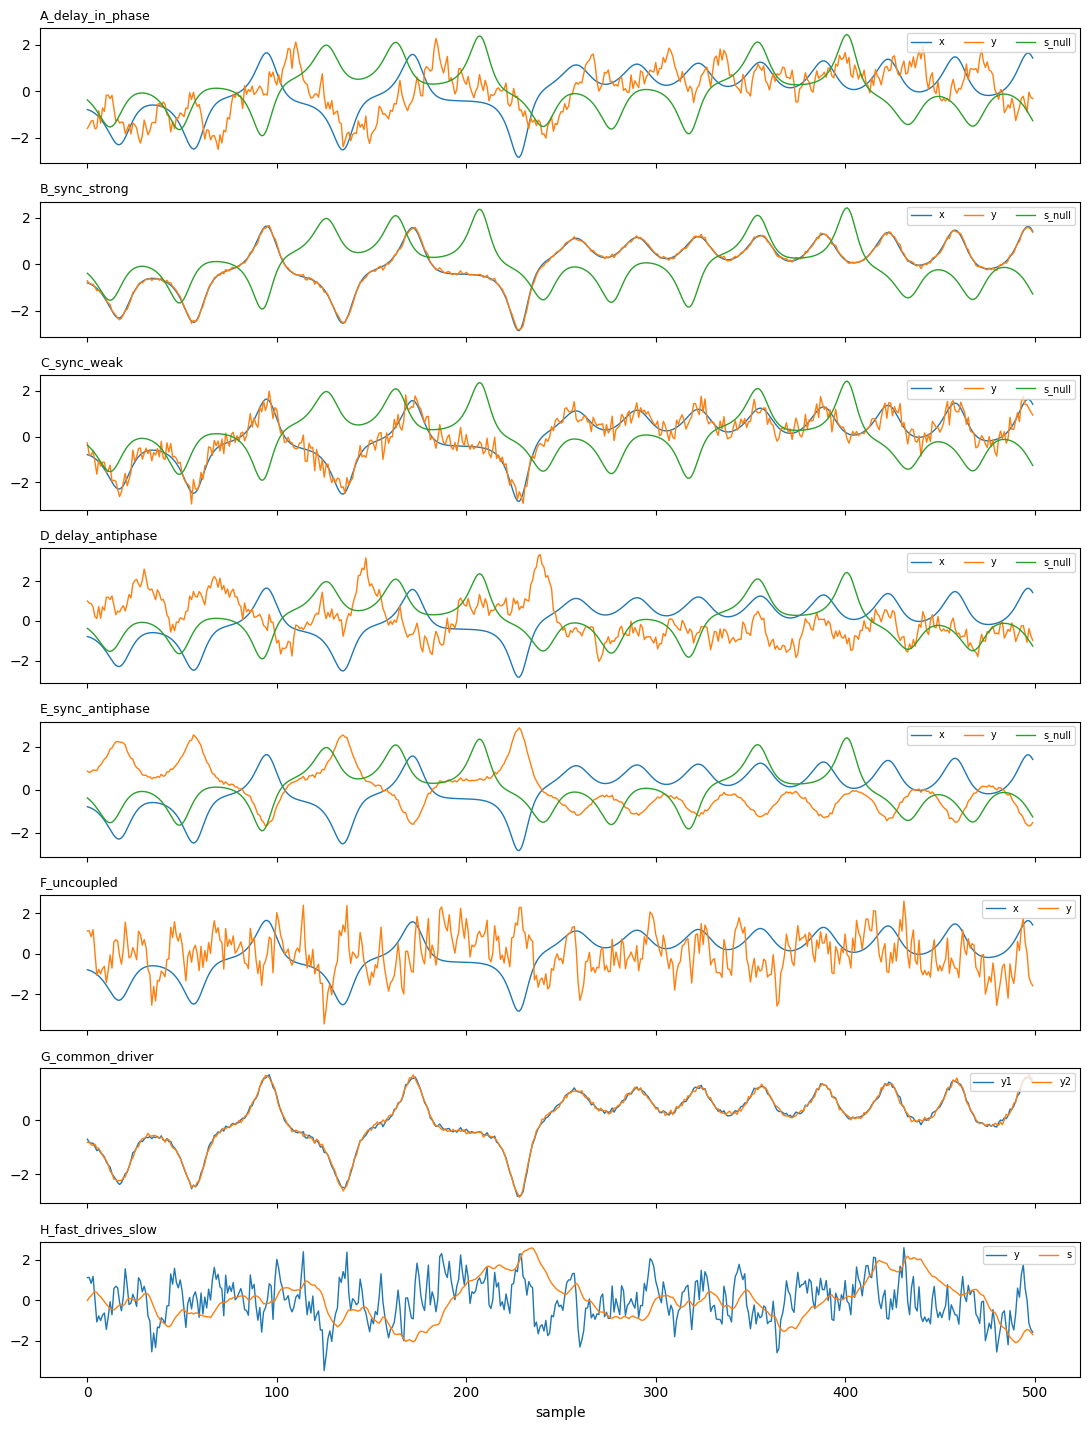

In [12]:
# ============ B.3 Generate the synthetic data (and save them as CSV) ============
DATA = {}
os.makedirs('validation_data', exist_ok=True)
t0 = time.time()
for sc in SCENARIOS:
    for seed in range(N_REAL):
        DATA[(sc, seed)] = scenario(sc, seed)
        DATA[(sc, seed)].to_csv(f'validation_data/{sc}_seed{seed:02d}.csv', index=False)
TRUTH.to_csv('validation_data/truth.csv', index=False)
print(f'{len(DATA)} synthetic datasets generated in {time.time() - t0:.0f} s')

# Visual check: first realization of each scenario (standardized, first 500 samples)
fig, axs = plt.subplots(len(SCENARIOS), 1, figsize=(11, 1.8 * len(SCENARIOS)), sharex=True)
for ax, sc in zip(axs, SCENARIOS):
    df = DATA[(sc, 0)].iloc[:500]
    for c in df.columns:
        ax.plot(((df[c] - df[c].mean()) / df[c].std()).values, lw=1, label=c)
    ax.set_title(sc, fontsize=9, loc='left'); ax.legend(fontsize=7, loc='upper right', ncol=3)
axs[-1].set_xlabel('sample'); plt.tight_layout(); plt.show()

In [13]:
# ============ B.4 Run SymVeR on every realization and compare with the ground truth ============
def success(v, r):
    if r.category != v.expected:
        return False
    if r.category == 'driver -> response':
        if r.slow_candidate != v.driver_or_slow: return False
        if pd.notna(v.true_delay) and abs(abs(r.tau) - v.true_delay) > 3: return False
    if r.category == 'synchronous slow-fast' and r.slow_candidate != v.driver_or_slow:
        return False
    return True

rows = []; t0 = time.time()
for sc in SCENARIOS:
    for seed in range(N_REAL):
        R, _ = symver(DATA[(sc, seed)], max_lag=MAXLAG_VAL, B=B_VAL, block=BLOCK_VAL, seed=seed)
        for _, v in TRUTH[TRUTH.scenario == sc].iterrows():
            r = R[((R.A == v.A) & (R.B == v.B)) | ((R.A == v.B) & (R.B == v.A))].iloc[0]
            rows.append(dict(scenario=sc, seed=seed, pair=f'{v.A}-{v.B}', expected=v.expected,
                             expected_limitation=v.expected_limitation, obtained=r.category,
                             tau=(r.tau if r.A == v.A else -r.tau), success=success(v, r)))
    print(f'{sc} done ({time.time() - t0:.0f} s)', flush=True)
VAL = pd.DataFrame(rows)
VAL.to_csv('validation_results.csv', index=False)

A_delay_in_phase done (96 s)
B_sync_strong done (191 s)
C_sync_weak done (287 s)
D_delay_antiphase done (383 s)
E_sync_antiphase done (480 s)
F_uncoupled done (544 s)
G_common_driver done (608 s)
H_fast_drives_slow done (670 s)


In [14]:
# ============ B.5 Success rates ============
def summary(V):
    out = []
    for (sc, pair), g in V.groupby(['scenario', 'pair'], sort=False):
        out.append({'scenario': sc, 'pair': pair, 'expected': g.expected.iloc[0],
                    'expected limitation': g.expected_limitation.iloc[0],
                    'successes': f'{int(g.success.sum())}/{len(g)}',
                    'outcomes obtained': ', '.join(f'{k}: {n}' for k, n in g.obtained.value_counts().items()),
                    'median tau': g.tau.median()})
    return pd.DataFrame(out)

S = summary(VAL)
display(S[~S.pair.str.contains('s_null')])
ctrl = VAL[VAL.pair.str.contains('s_null')]
valid = VAL[~VAL.expected_limitation & ~VAL.pair.str.contains('s_null')]
print(f'Control pairs with s_null (expected: no coupling): false positives '
      f'{int((ctrl.obtained != "no coupling").sum())}/{len(ctrl)}')
print(f'Scenarios without expected limitation: {int(valid.success.sum())}/{len(valid)} correct '
      f'({100 * valid.success.mean():.0f}%)')

,scenario,pair,expected,expected limitation,successes,outcomes obtained,median tau
0,A_delay_in_phase,x-y,driver -> response,False,9/10,driver -> response: 10,13.0
3,B_sync_strong,x-y,synchronous slow-fast,False,10/10,synchronous slow-fast: 10,0.0
6,C_sync_weak,x-y,synchronous slow-fast,False,6/10,"synchronous slow-fast: 6, no coupling: 4",0.0
9,D_delay_antiphase,x-y,driver -> response,True,0/10,"no coupling: 8, coupled, no timescale hierarch...",-6.5
12,E_sync_antiphase,x-y,synchronous slow-fast,True,0/10,no coupling: 10,20.0
15,F_uncoupled,x-y,no coupling,False,9/10,"no coupling: 9, coupled, no timescale hierarch...",-19.0
16,G_common_driver,y1-y2,no coupling,True,3/10,"coupled, no timescale hierarchy: 7, no couplin...",0.0
17,H_fast_drives_slow,y-s,driver -> response,True,0/10,"coupled, no timescale hierarchy: 10",1.0


Control pairs with s_null (expected: no coupling): false positives 5/100
Scenarios without expected limitation: 34/40 correct (85%)


In [15]:
# ============ B.6 Success rate by branch of the procedure ============
BRANCH = {'A_delay_in_phase': 'lag branch (tau != 0)', 'D_delay_antiphase': 'lag branch (tau != 0)',
          'H_fast_drives_slow': 'lag branch (tau != 0)', 'I_same_scale': 'lag branch (tau != 0)',
          'B_sync_strong': 'synchronous branch (tau = 0)', 'C_sync_weak': 'synchronous branch (tau = 0)',
          'E_sync_antiphase': 'synchronous branch (tau = 0)',
          'F_uncoupled': 'no coupling expected', 'G_common_driver': 'no coupling expected'}
V2 = VAL.copy()
V2['branch'] = np.where(V2.pair.str.contains('s_null'), 'no coupling expected (s_null controls)', V2.scenario.map(BRANCH))
V2['case'] = np.where(V2.expected_limitation, 'expected limitation', 'valid scenario')
tab = (V2.groupby(['branch', 'case'])
         .agg(successes=('success', 'sum'), pairs=('success', 'size'))
         .assign(rate=lambda d: (100 * d.successes / d.pairs).round(0).astype(int).astype(str) + ' %'))
display(tab)


successes  pairs  rate
branch                                 case                                       
lag branch (tau != 0)                  expected limitation          0     20   0 %
                                       valid scenario               9     10  90 %
no coupling expected                   expected limitation          3     10  30 %
                                       valid scenario               9     10  90 %
no coupling expected (s_null controls) valid scenario              95    100  95 %
synchronous branch (tau = 0)           expected limitation          0     10   0 %
                                       valid scenario              16     20  80 %

In [16]:
# ============ B.7 Detailed table: truth vs result for every synthetic dataset ============
SHOW_NULL_PAIRS = False   # True: also list the control pairs with s_null (expected: no coupling)

def _other(v, name):
    # The variable of the pair that is not `name`
    return v.B if name == v.A else v.A

def _truth_text(v):
    # The true relationship of the pair, in words
    if v.expected == 'driver -> response':
        txt = f'{v.driver_or_slow} drives {_other(v, v.driver_or_slow)}'
        return txt + (' (anti-phase)' if v.scenario.startswith('D_') else '')
    if v.expected == 'synchronous slow-fast':
        txt = f'{v.driver_or_slow} slow, {_other(v, v.driver_or_slow)} fast, synchronous'
        return txt + (' (anti-phase)' if v.scenario.startswith('E_') else '')
    if v.expected == 'no coupling':
        return 'no coupling' + (' (common hidden driver)' if v.scenario.startswith('G_') else '')
    return 'coupled, same timescale'

def _found_text(r, v):
    # What SymVeR found, in words (tau in VAL is oriented as the pair A-B of TRUTH: tau > 0 means A leads)
    if r.obtained == 'no coupling':
        return 'no coupling'
    if r.obtained == 'coupled, no timescale hierarchy':
        return 'coupled, no hierarchy'
    if r.obtained == 'driver -> response':
        drv, rsp = (v.A, v.B) if r.tau > 0 else (v.B, v.A)
        return f'{drv} drives {rsp}'
    # synchronous slow-fast: the slow variable found is the true one if the result was judged correct
    if v.driver_or_slow is None:
        return 'synchronous slow-fast'
    slow = v.driver_or_slow if r.success else _other(v, v.driver_or_slow)
    return f'{slow} slow, {_other(v, slow)} fast, synchronous'

rows = []
for _, r in VAL.iterrows():
    if not SHOW_NULL_PAIRS and 's_null' in r.pair:
        continue
    a, b = r.pair.split('-', 1)
    v = TRUTH[(TRUTH.scenario == r.scenario) & (TRUTH.A == a) & (TRUTH.B == b)].iloc[0]
    rows.append({'dataset': f'{r.scenario} #{r.seed}',
                 'pair': r.pair,
                 'truth': _truth_text(v),
                 'found': _found_text(r, v),
                 'true lag': '-' if pd.isna(v.true_delay) else int(v.true_delay),
                 'found lag': '-' if r.obtained == 'no coupling' else int(abs(r.tau)),
                 'correct': 'yes' if r.success else 'NO',
                 'expected limitation': 'yes' if r.expected_limitation else ''})
DETAIL = pd.DataFrame(rows)
display(DETAIL)
DETAIL.to_csv('validation_detail.csv', index=False)

,dataset,pair,truth,found,true lag,found lag,correct,expected limitation
0,A_delay_in_phase #0,x-y,x drives y,x drives y,10,11,yes,
1,A_delay_in_phase #1,x-y,x drives y,x drives y,10,13,yes,
2,A_delay_in_phase #2,x-y,x drives y,x drives y,10,14,NO,
3,A_delay_in_phase #3,x-y,x drives y,x drives y,10,11,yes,
4,A_delay_in_phase #4,x-y,x drives y,x drives y,10,13,yes,
5,A_delay_in_phase #5,x-y,x drives y,x drives y,10,11,yes,
6,A_delay_in_phase #6,x-y,x drives y,x drives y,10,12,yes,
7,A_delay_in_phase #7,x-y,x drives y,x drives y,10,13,yes,
8,A_delay_in_phase #8,x-y,x drives y,x drives y,10,13,yes,
9,A_delay_in_phase #9,x-y,x drives y,x drives y,10,13,yes,


noise 0.1 done (98 s)
noise 0.05 done (197 s)
noise 0.02 done (299 s)

Summary (correct = synchronous slow-fast with mu as the slow variable):


correct  realizations  median_gap  min_gap  max_gap
noise s response                                                         
0.02    x_bistable          7            10      0.3400    0.180    0.785
        y_monostable        8            10      0.0095    0.008    0.011
0.05    x_bistable          7            10      0.3460    0.186    0.783
        y_monostable        6            10      0.0100    0.009    0.012
0.10    x_bistable          6            10      0.3560    0.201    0.762
        y_monostable        3            10      0.0135    0.010    0.020

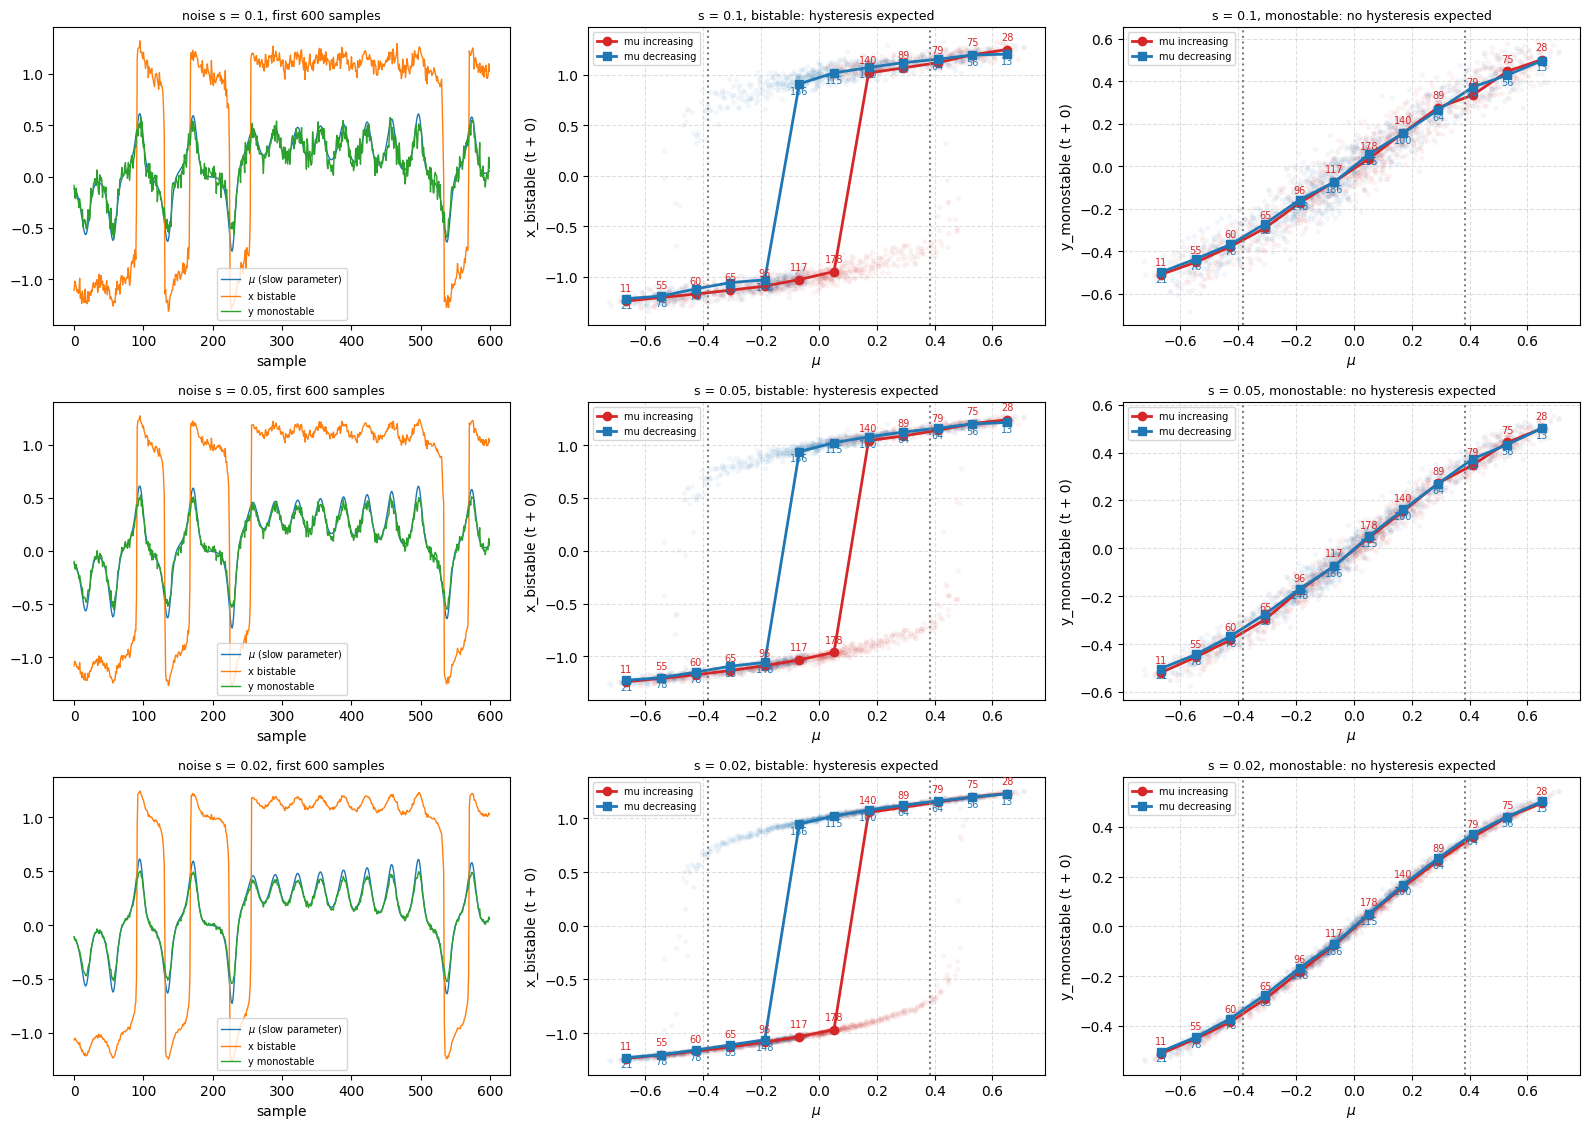

In [17]:
# ============ B.8 Hysteresis test: bistable system eps dx = (mu + x - x^3) dt + noise ============
# The slow parameter mu(t) is the Lorenz x component rescaled to about [-0.8, 0.8] (aperiodic, as in the other
# scenarios; a strictly periodic mu cannot be tested with circular-shift surrogates, because shifts by one period
# reproduce the coupling). mu crosses the bistable range |mu| < 2/(3 sqrt 3) ~ 0.385 irregularly.
#   bistable  :  eps dx = ( mu + x - x^3 ) dt + s sqrt(eps) dW
#                two stable branches coexist for |mu| < 0.385: x stays on its branch until mu passes a fold,
#                then jumps -> hysteresis (lower branch while mu increases, upper branch while it decreases)
#   monostable:  eps dy = ( mu - y - y^3 ) dt + s sqrt(eps) dW
#                control: same cubic nonlinearity, one stable state for every mu -> single-valued, no hysteresis
# Same mu(t), same time constant eps = EPS_S (fast) and same noise: the only difference is bistability.
# Expected: SymVeR finds "mu slow <-> x fast, synchronous" and "mu slow <-> y fast, synchronous";
# the hysteresis plot (lag 0) shows two separated branches for x and overlapping branches for y.
# The noise intensity s is varied, because SymVeR works on increments and needs them above the noise.
H_SCALE = 0.04                         # mu = 0.04 * Lorenz x  ->  mu in about [-0.8, 0.8]
H_NOISE = [0.1, 0.05, 0.02]            # dynamic noise intensities s (all reported)
H_REAL = 3 if QUICK else 10

def hysteresis_system(seed, s):
    rng = np.random.default_rng(seed)
    mu = H_SCALE * lorenz_x(rng)                       # same generator, step DT and length STEPS as Part B
    x = np.empty(STEPS); y = np.empty(STEPS)
    x[0] = 1.0 if mu[0] < 0 else -1.0                 # start on a branch that exists for the initial mu
    y[0] = 0.0
    k = s / np.sqrt(EPS_S) * np.sqrt(DT)
    for i in range(STEPS - 1):
        x[i + 1] = x[i] + DT * (mu[i] + x[i] - x[i] ** 3) / EPS_S + k * rng.normal()
        y[i + 1] = y[i] + DT * (mu[i] - y[i] - y[i] ** 3) / EPS_S + k * rng.normal()
    return sample({'mu': mu, 'x_bistable': x, 'y_monostable': y})

def branch_gap(df, driver, response, bins=12, min_count=5):
    # Mean absolute difference between the median response while the driver increases and while it decreases,
    # over the driver bins where both medians exist (about 0 = no hysteresis). Internal check only.
    d = pd.DataFrame({'D': df[driver].values, 'Y': df[response].values,
                      'dirn': ternarize(df[driver].values)}).dropna()
    d['bin'] = pd.cut(d.D, bins)
    m = d[d.dirn != 0].groupby(['bin', 'dirn'], observed=True).Y.agg(['median', 'size'])
    m = m[m['size'] >= min_count]['median'].unstack().dropna()
    return float((m[1.0] - m[-1.0]).abs().mean()) if {1.0, -1.0} <= set(m.columns) and len(m) else np.nan

HDATA, rows = {}, []
t0 = time.time()
for s in H_NOISE:
    for seed in range(H_REAL):
        df = hysteresis_system(seed, s); HDATA[(s, seed)] = df
        R, _ = symver(df, max_lag=MAXLAG_VAL, B=B_VAL, block=BLOCK_VAL, seed=seed)
        for resp in ['x_bistable', 'y_monostable']:
            r_ = R[((R.A == 'mu') & (R.B == resp)) | ((R.A == resp) & (R.B == 'mu'))].iloc[0]
            rows.append({'noise s': s, 'realization': seed, 'response': resp, 'SymVeR outcome': r_.outcome,
                         'correct': r_.category == 'synchronous slow-fast' and r_.slow_candidate == 'mu',
                         'branch gap': round(branch_gap(df, 'mu', resp), 3)})
    print(f'noise {s} done ({time.time() - t0:.0f} s)', flush=True)
HYS = pd.DataFrame(rows)
HYS.to_csv('hysteresis_test_results.csv', index=False)
print('\nSummary (correct = synchronous slow-fast with mu as the slow variable):')
display(HYS.groupby(['noise s', 'response']).agg(correct=('correct', 'sum'), realizations=('correct', 'size'),
                                                 median_gap=('branch gap', 'median'),
                                                 min_gap=('branch gap', 'min'), max_gap=('branch gap', 'max')))

# Plots for the first realization at each noise level (lag 0, slow parameter mu on the x axis)
fig, axs = plt.subplots(len(H_NOISE), 3, figsize=(16, 3.8 * len(H_NOISE)), squeeze=False)
for row, s in zip(axs, H_NOISE):
    df = HDATA[(s, 0)]
    row[0].plot(df.mu.values[:600], label=r'$\mu$ (slow parameter)', lw=1)
    row[0].plot(df.x_bistable.values[:600], label='x bistable', lw=1)
    row[0].plot(df.y_monostable.values[:600], label='y monostable', lw=1)
    row[0].set_xlabel('sample'); row[0].legend(fontsize=7); row[0].set_title(f'noise s = {s}, first 600 samples', fontsize=9)
    for ax, resp, lab in [(row[1], 'x_bistable', 'bistable: hysteresis expected'),
                          (row[2], 'y_monostable', 'monostable: no hysteresis expected')]:
        plot_hysteresis(df, 'mu', resp, 0, ax=ax, num_bins=12)
        ax.set_xlabel(r'$\mu$')                              # LaTeX label on the axis, plain name in the data
        ax.set_title(f's = {s}, {lab}', fontsize=9)
        for f in (-2 / (3 * np.sqrt(3)), 2 / (3 * np.sqrt(3))):
            ax.axvline(f, color='gray', ls=':')
plt.tight_layout(); plt.savefig('hysteresis_test.png', dpi=110); plt.show()

N = 500 done (64 s)
N = 1000 done (213 s)
N = 2000 done (598 s)
N = 4000 done (3537 s)
RR = 3% done (3922 s)
RR = 5% done (4305 s)
RR = 10% done (4696 s)
Correct outcomes vs series length (RR = 5%):


scenario,A_delay_in_phase,B_sync_strong,C_sync_weak,F_uncoupled,"false couplings (s_null, A-C)"
N,,,,,
500,7/10,9/10,1/10,6/10,5/60
1000,9/10,8/10,3/10,8/10,3/60
2000,9/10,10/10,6/10,9/10,5/60
4000,9/10,10/10,8/10,9/10,4/60


Correct outcomes vs recurrence rate (N = 2000):


scenario,A_delay_in_phase,B_sync_strong,C_sync_weak,F_uncoupled,"false couplings (s_null, A-C)"
3%,9/10,10/10,6/10,9/10,5/60
5%,9/10,10/10,6/10,9/10,5/60
10%,9/10,10/10,6/10,9/10,5/60


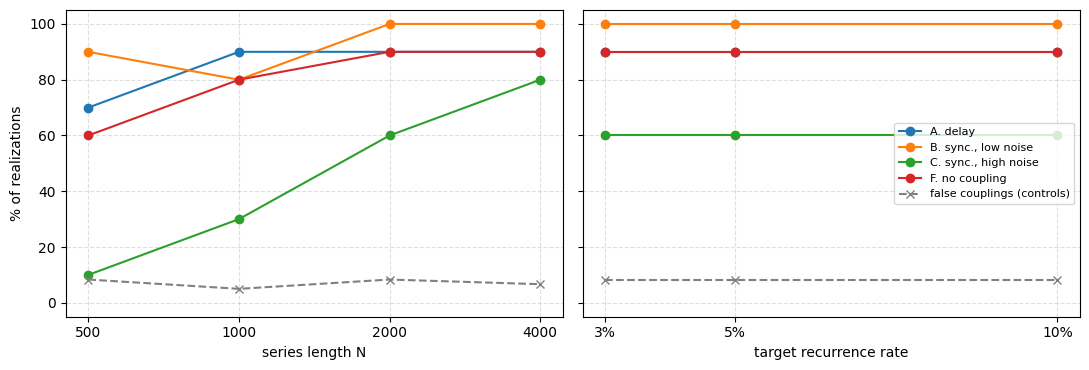

In [18]:
# ============ B.9 Robustness: series length and recurrence rate ============
# How do the results of the validation change with
#   (1) the length of the series, N in ROB_N (recurrence rate fixed at 5%);
#   (2) the target recurrence rate used to choose epsilon for the trapping time, RR in ROB_RR (N = 2000)?
# Only the scenarios inside the scope of the method are used: A (delay), B (synchronous, low noise),
# C (synchronous, high noise), F (no coupling), plus the s_null negative controls of A-C.
# The generators and all other settings are those of B.1-B.2 (same Lorenz driver, same relaxation dynamics,
# same seeds), so the case N = 2000, RR = 5% reproduces the results of B.4.
# The bootstrap block is scaled with the series length (N / 10, i.e. 200 samples for N = 2000).
# Needs cells A.1-A.5, B.1, B.2 and the function success() of B.4.
# Run time: about 50 min (ROB_QUICK = True: about 10 min, indicative only).
ROB_QUICK = False
ROB_N  = [500, 1000, 2000, 4000]
ROB_RR = [0.03, 0.05, 0.10]
ROB_SCEN = ['A_delay_in_phase', 'B_sync_strong', 'C_sync_weak', 'F_uncoupled']
ROB_SEEDS = range(3 if ROB_QUICK else N_REAL)
ROB_B = 60 if ROB_QUICK else B_VAL    # B >= 60 keeps the smallest p-value below 0.05 after BH

def _gen(name, seed, n):
    # Same generators as B.2, for a series of n samples (identical to scenario() when n = N).
    steps = int(BURN / DT) + n * EVERY + STEPS_LAG
    rng = np.random.default_rng(seed)
    def lorenz():
        s, r, b = 10., 28., 8 / 3
        f = lambda u: np.array([s * (u[1] - u[0]), u[0] * (r - u[2]) - u[1], u[0] * u[1] - b * u[2]])
        u = rng.normal(0, 5, 3) + np.array([0, 0, 25]); out = np.empty(steps)
        for i in range(steps):
            k1 = f(u); k2 = f(u + DT / 2 * k1); k3 = f(u + DT / 2 * k2); k4 = f(u + DT * k3)
            u = u + DT / 6 * (k1 + 2 * k2 + 2 * k3 + k4); out[i] = u[0]
        return out
    def follow(target, eps, sigma, delay_steps=0):
        y = np.zeros(steps); k = sigma / np.sqrt(eps) * np.sqrt(DT)
        y[:delay_steps + 1] = target[0]
        for i in range(delay_steps, steps - 1):
            y[i + 1] = y[i] + DT * (-y[i] + target[i - delay_steps]) / eps + k * rng.normal()
        return y
    x = lorenz(); s_null = lorenz(); zero = np.zeros(steps)
    if name == 'A_delay_in_phase': ser = {'x': x, 'y': follow(x, EPS, 5.0, STEPS_LAG), 's_null': s_null}
    elif name == 'B_sync_strong':  ser = {'x': x, 'y': follow(x, EPS_S, 0.5), 's_null': s_null}
    elif name == 'C_sync_weak':    ser = {'x': x, 'y': follow(x, EPS_S, 3.0), 's_null': s_null}
    elif name == 'F_uncoupled':    ser = {'x': x, 'y': follow(zero, EPS, 5.0)}
    else: raise ValueError(name)
    start = int(BURN / DT) + STEPS_LAG
    idx = np.arange(start, start + n * EVERY, EVERY)
    return pd.DataFrame({k: v[idx] for k, v in ser.items()})

def _run(df, seed, n, rr):
    # SymVeR with target recurrence rate rr (eps_for_rr reads its default target, so it is set and restored).
    old = eps_for_rr.__defaults__
    eps_for_rr.__defaults__ = (rr,) + old[1:]
    try:
        R, _ = symver(df, max_lag=MAXLAG_VAL, B=ROB_B, block=max(n // 10, 2 * MAXLAG_VAL), seed=seed)
    finally:
        eps_for_rr.__defaults__ = old
    return R

def _evaluate(R, sc, seed, n, rr, study):
    rows = []
    for _, v in TRUTH[TRUTH.scenario == sc].iterrows():
        r = R[((R.A == v.A) & (R.B == v.B)) | ((R.A == v.B) & (R.B == v.A))].iloc[0]
        rows.append(dict(study=study, N=n, RR=rr, scenario=sc, seed=seed, pair=f'{v.A}-{v.B}',
                         control='s_null' in f'{v.A}-{v.B}', obtained=r.category,
                         tau=(r.tau if r.A == v.A else -r.tau), success=success(v, r)))
    return rows

rows = []; t0 = time.time()
for n in ROB_N:                                       # (1) series length, RR = 5%
    for sc in ROB_SCEN:
        for seed in ROB_SEEDS:
            df = _gen(sc, seed, n)
            rows += _evaluate(_run(df, seed, n, 0.05), sc, seed, n, 0.05, 'length')
    print(f'N = {n} done ({time.time() - t0:.0f} s)', flush=True)
for rr in ROB_RR:                                     # (2) recurrence rate, N = 2000
    for sc in ROB_SCEN:
        for seed in ROB_SEEDS:
            df = _gen(sc, seed, 2000)
            rows += _evaluate(_run(df, seed, 2000, rr), sc, seed, 2000, rr, 'recurrence rate')
    print(f'RR = {rr:.0%} done ({time.time() - t0:.0f} s)', flush=True)
ROB = pd.DataFrame(rows)
ROB.to_csv('robustness_results.csv', index=False)

# ---------- tables ----------
def _rate(g):
    return f'{int(g.success.sum())}/{len(g)}'

def _tables(study, col):
    d = ROB[ROB.study == study]
    tab = d[~d.control].groupby([col, 'scenario'], sort=False).apply(_rate).unstack().reindex(columns=ROB_SCEN)
    fp = d[d.control].groupby(col).apply(lambda g: f'{int((g.obtained != "no coupling").sum())}/{len(g)}')
    tab['false couplings (s_null, A-C)'] = fp
    return tab

TAB_N = _tables('length', 'N'); TAB_RR = _tables('recurrence rate', 'RR')
TAB_RR.index = [f'{r:.0%}' for r in TAB_RR.index]
print('Correct outcomes vs series length (RR = 5%):');      display(TAB_N)
print('Correct outcomes vs recurrence rate (N = 2000):');  display(TAB_RR)
TAB_N.to_csv('robustness_length.csv'); TAB_RR.to_csv('robustness_rr.csv')

# ---------- figure ----------
labels = {'A_delay_in_phase': 'A. delay', 'B_sync_strong': 'B. sync., low noise',
          'C_sync_weak': 'C. sync., high noise', 'F_uncoupled': 'F. no coupling'}
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, study, col in [(axs[0], 'length', 'N'), (axs[1], 'recurrence rate', 'RR')]:
    d = ROB[(ROB.study == study) & ~ROB.control]
    for sc in ROB_SCEN:
        m = d[d.scenario == sc].groupby(col).success.mean()
        ax.plot(m.index, 100 * m.values, marker='o', label=labels[sc])
    c = ROB[(ROB.study == study) & ROB.control].groupby(col).apply(lambda g: (g.obtained != 'no coupling').mean())
    ax.plot(c.index, 100 * c.values, marker='x', ls='--', color='gray', label='false couplings (controls)')
    ax.set_xlabel('series length N' if col == 'N' else 'target recurrence rate')
    if col == 'N': ax.set_xscale('log'); ax.set_xticks(ROB_N); ax.set_xticklabels(ROB_N)
    else: ax.set_xticks(ROB_RR); ax.set_xticklabels([f'{r:.0%}' for r in ROB_RR])
    ax.grid(ls='--', alpha=.4)
    ax.minorticks_off();
axs[0].set_ylabel('% of realizations'); axs[0].set_ylim(-5, 105)
axs[1].legend(fontsize=8, loc='center right')
plt.tight_layout(); plt.savefig('robustness.png', dpi=200, bbox_inches='tight'); plt.show()

sampling every 10 steps (0.01 time units) done (369 s)
sampling every 20 steps (0.02 time units) done (759 s)
sampling every 40 steps (0.04 time units) done (1169 s)
sampling every 80 steps (0.08 time units) done (1650 s)
Correct outcomes vs sampling interval (N = 2000; true delay in A = 0.2 time units):


scenario,A_delay_in_phase,B_sync_strong,C_sync_weak,F_uncoupled,"false couplings (s_null, A-C)",A: median delay (samples),A: median delay (time units)
sampling interval,,,,,,,
0.01,9/10,7/10,4/10,9/10,5/60,25.0,0.25
0.02,9/10,10/10,6/10,9/10,5/60,13.0,0.26
0.04,7/10,10/10,9/10,10/10,3/60,6.0,0.24
0.08,10/10,10/10,10/10,10/10,1/60,3.0,0.24


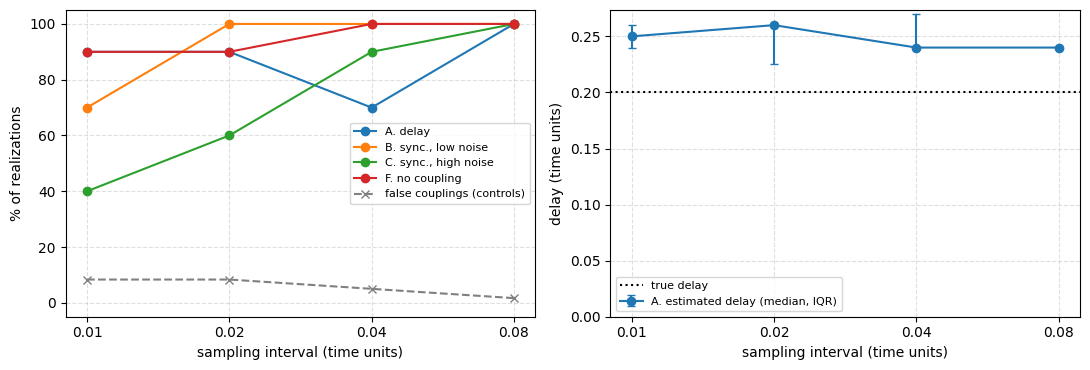

In [19]:
# ============ B.10 Sensitivity to the sampling interval ============
# The symbols are the signs of the increments between consecutive samples, so they depend on the sampling interval.
# Here the same continuous systems of B.2 (same Lorenz driver, same relaxation dynamics, same physical delay
# STEPS_LAG * DT = 0.2 time units, same seeds) are sampled every SAMP_EVERY integration steps, with N = 2000 samples.
# The number of samples is fixed, so only the sampling interval changes (the observed time span grows with it).
# Quantities defined in time are kept fixed in time units:
#   - the maximum lag of the coupling test (MAXLAG_VAL samples at EVERY = 20, i.e. 0.6 time units);
#   - the tolerance on the estimated delay (3 samples at EVERY = 20, i.e. 0.06 time units).
# Expected: the delay in samples scales with 1 / interval, the delay in time units stays constant,
# and the identification of the slow variable does not change.
# Scenarios A, B, C, F plus the s_null controls of A-C. EVERY = 20 reproduces B.4.
# Needs cells A.1-A.5, B.1, B.2 and B.4 (TRUTH). Run time: about 35-45 min (SAMP_QUICK = True: about 8 min).
SAMP_QUICK = False
SAMP_EVERY = [10, 20, 40, 80]                  # sampling interval in integration steps (DT = 1e-3)
SAMP_SCEN  = ['A_delay_in_phase', 'B_sync_strong', 'C_sync_weak', 'F_uncoupled']
SAMP_SEEDS = range(3 if SAMP_QUICK else N_REAL)
SAMP_B     = 60 if SAMP_QUICK else B_VAL
SAMP_N     = N                                 # 2000 samples

def _gen_every(name, seed, every, n=SAMP_N):
    # Same generators as B.2, sampled every `every` steps (identical to scenario() when every = EVERY).
    steps = int(BURN / DT) + n * every + STEPS_LAG
    rng = np.random.default_rng(seed)
    def lorenz():
        s, r, b = 10., 28., 8 / 3
        f = lambda u: np.array([s * (u[1] - u[0]), u[0] * (r - u[2]) - u[1], u[0] * u[1] - b * u[2]])
        u = rng.normal(0, 5, 3) + np.array([0, 0, 25]); out = np.empty(steps)
        for i in range(steps):
            k1 = f(u); k2 = f(u + DT / 2 * k1); k3 = f(u + DT / 2 * k2); k4 = f(u + DT * k3)
            u = u + DT / 6 * (k1 + 2 * k2 + 2 * k3 + k4); out[i] = u[0]
        return out
    def follow(target, eps, sigma, delay_steps=0):
        y = np.zeros(steps); k = sigma / np.sqrt(eps) * np.sqrt(DT)
        y[:delay_steps + 1] = target[0]
        for i in range(delay_steps, steps - 1):
            y[i + 1] = y[i] + DT * (-y[i] + target[i - delay_steps]) / eps + k * rng.normal()
        return y
    x = lorenz(); s_null = lorenz(); zero = np.zeros(steps)
    if name == 'A_delay_in_phase': ser = {'x': x, 'y': follow(x, EPS, 5.0, STEPS_LAG), 's_null': s_null}
    elif name == 'B_sync_strong':  ser = {'x': x, 'y': follow(x, EPS_S, 0.5), 's_null': s_null}
    elif name == 'C_sync_weak':    ser = {'x': x, 'y': follow(x, EPS_S, 3.0), 's_null': s_null}
    elif name == 'F_uncoupled':    ser = {'x': x, 'y': follow(zero, EPS, 5.0)}
    else: raise ValueError(name)
    start = int(BURN / DT) + STEPS_LAG
    idx = np.arange(start, start + n * every, every)
    return pd.DataFrame({k: v[idx] for k, v in ser.items()})

def _success_every(v, r, every):
    # As success() of B.4, with the delay compared in integration steps instead of samples.
    if r.category != v.expected:
        return False
    if r.category == 'driver -> response':
        if r.slow_candidate != v.driver_or_slow: return False
        if pd.notna(v.true_delay) and abs(abs(r.tau) * every - v.true_delay * EVERY) > 3 * EVERY: return False
    if r.category == 'synchronous slow-fast' and r.slow_candidate != v.driver_or_slow:
        return False
    return True

rows = []; t0 = time.time()
for every in SAMP_EVERY:
    max_lag = int(round(MAXLAG_VAL * EVERY / every))          # 0.6 time units
    for sc in SAMP_SCEN:
        for seed in SAMP_SEEDS:
            df = _gen_every(sc, seed, every)
            R, _ = symver(df, max_lag=max_lag, B=SAMP_B, block=SAMP_N // 10, seed=seed)
            for _, v in TRUTH[TRUTH.scenario == sc].iterrows():
                r = R[((R.A == v.A) & (R.B == v.B)) | ((R.A == v.B) & (R.B == v.A))].iloc[0]
                rows.append(dict(every=every, dt_sample=every * DT, scenario=sc, seed=seed, pair=f'{v.A}-{v.B}',
                                 control='s_null' in f'{v.A}-{v.B}', obtained=r.category,
                                 tau=(r.tau if r.A == v.A else -r.tau), success=_success_every(v, r, every)))
    print(f'sampling every {every} steps ({every * DT:g} time units) done ({time.time() - t0:.0f} s)', flush=True)
SAMP = pd.DataFrame(rows)
SAMP.to_csv('sampling_results.csv', index=False)

# ---------- table ----------
d = SAMP[~SAMP.control]
TAB_S = d.groupby(['dt_sample', 'scenario'], sort=False).apply(lambda g: f'{int(g.success.sum())}/{len(g)}') \
         .unstack().reindex(columns=SAMP_SCEN)
TAB_S['false couplings (s_null, A-C)'] = SAMP[SAMP.control].groupby('dt_sample') \
         .apply(lambda g: f'{int((g.obtained != "no coupling").sum())}/{len(g)}')
dA = d[(d.scenario == 'A_delay_in_phase') & (d.obtained == 'driver -> response')]
dA = dA.assign(lag=np.abs(dA.tau), delay=np.abs(dA.tau) * dA.dt_sample)
TAB_S['A: median delay (samples)'] = dA.groupby('dt_sample').lag.median()
TAB_S['A: median delay (time units)'] = dA.groupby('dt_sample').delay.median()
TAB_S.index.name = 'sampling interval'
print(f'Correct outcomes vs sampling interval (N = {SAMP_N}; true delay in A = {STEPS_LAG * DT:g} time units):')
display(TAB_S)
TAB_S.to_csv('sampling_table.csv')

# ---------- figure ----------
labels = {'A_delay_in_phase': 'A. delay', 'B_sync_strong': 'B. sync., low noise',
          'C_sync_weak': 'C. sync., high noise', 'F_uncoupled': 'F. no coupling'}
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
ax = axs[0]
for sc in SAMP_SCEN:
    m = d[d.scenario == sc].groupby('dt_sample').success.mean()
    ax.plot(m.index, 100 * m.values, marker='o', label=labels[sc])
c = SAMP[SAMP.control].groupby('dt_sample').apply(lambda g: (g.obtained != 'no coupling').mean())
ax.plot(c.index, 100 * c.values, marker='x', ls='--', color='gray', label='false couplings (controls)')
ax.set_ylabel('% of realizations'); ax.set_ylim(-5, 105); ax.legend(fontsize=8)
ax = axs[1]                                           # estimated delay of scenario A in time units
g = dA.groupby('dt_sample').delay
q = g.quantile([0.25, 0.5, 0.75]).unstack()
ax.errorbar(q.index, q[0.5], yerr=[q[0.5] - q[0.25], q[0.75] - q[0.5]], marker='o', capsize=3,
            color='C0', label='A. estimated delay (median, IQR)')
ax.axhline(STEPS_LAG * DT, color='k', ls=':', label='true delay')
ax.set_ylabel('delay (time units)'); ax.set_ylim(bottom=0); ax.legend(fontsize=8)
for ax in axs:
    ax.set_xscale('log'); ax.minorticks_off()
    ax.set_xticks([e * DT for e in SAMP_EVERY]); ax.set_xticklabels([f'{e * DT:g}' for e in SAMP_EVERY])
    ax.set_xlabel('sampling interval (time units)'); ax.grid(ls='--', alpha=.4)
plt.tight_layout(); plt.savefig('sampling.png', dpi=200, bbox_inches='tight'); plt.show()

In [20]:
SAMP[(SAMP.scenario == 'A_delay_in_phase') & ~SAMP.control & ~SAMP.success][['dt_sample', 'seed', 'obtained', 'tau']]

,dt_sample,seed,obtained,tau
0,0.01,0,driver -> response,29
106,0.02,2,driver -> response,14
206,0.04,2,driver -> response,7
212,0.04,4,driver -> response,7
227,0.04,9,driver -> response,7


# Part C — Application to EMA and SMEAR

Parameters are fixed before looking at the results. Each cell is skipped if its data file is not in the notebook folder.

In [22]:
# ============ C.1 EMA ============
# Single-subject EMA dataset (28 items). Preprocessing:
#   - dates read as day/month/year;
#   - rows kept only if all 28 items are present;
#   - breaks at every change of day (no increments or runs across the night).
EMA_FILE = 'ESMdata.csv'
ITEMS = ['mood_relaxed', 'mood_down', 'mood_irritat', 'mood_satisfi', 'mood_lonely', 'mood_anxious',
         'mood_enthus', 'mood_suspic', 'mood_cheerf', 'mood_guilty', 'mood_doubt', 'mood_strong',
         'pat_restl', 'pat_agitate', 'pat_worry', 'pat_concent', 'se_selflike', 'se_ashamed',
         'se_selfdoub', 'se_handle', 'phy_hungry', 'phy_tired', 'phy_pain', 'phy_dizzy',
         'phy_drymouth', 'phy_nauseous', 'phy_headache', 'phy_sleepy']

if os.path.exists(EMA_FILE):
    ema = pd.read_csv(EMA_FILE)
    ema['day'] = pd.to_datetime(ema['date'], format='%d/%m/%y')
    ema['dt'] = ema['day'] + pd.to_timedelta(ema['resptime_e'].astype(str), errors='coerce')
    ema = ema.dropna(subset=['dt'] + ITEMS).sort_values('dt').reset_index(drop=True)
    ema_breaks = (ema['day'] != ema['day'].shift()).values
    print(f'{len(ema)} responses over {ema_breaks.sum()} days')
    t0 = time.time()
    R_ema, U_ema = symver(ema[ITEMS], breaks=ema_breaks, max_lag=30, B=1000, block=42, seed=1)
    print(f'done in {time.time() - t0:.0f} s')
    print('\nOutcome counts:'); print(R_ema.category.value_counts().to_string())
    print('\nVariable table (RR_eff = effective recurrence rate of the raw series):')
    display(U_ema.round(3))
    print('\nPairs with a timescale hierarchy:')
    display(show(R_ema[R_ema.hierarchy]))
    R_ema.to_csv('EMA_symver_results.csv', index=False)
    U_ema.to_csv('RR_results_EMA.csv', index = True)
else:
    print(f'{EMA_FILE} not found: skipping EMA.')

1471 responses over 238 days
done in 13 s

Outcome counts:
category
no coupling                        208
synchronous slow-fast               90
coupled, no timescale hierarchy     52
driver -> response                  28

Variable table (RR_eff = effective recurrence rate of the raw series):


,TT,Lam,RR_eff
mood_relaxed,2.725,0.468,0.377
mood_down,3.541,0.691,0.491
mood_irritat,2.449,0.344,0.274
mood_satisfi,2.563,0.380,0.297
mood_lonely,4.505,0.881,0.711
mood_anxious,5.085,0.942,0.834
mood_enthus,2.723,0.446,0.324
mood_suspic,4.701,0.875,0.648
mood_cheerf,2.705,0.450,0.330
mood_guilty,4.170,0.856,0.683



Pairs with a timescale hierarchy:


,A,B,tau,test,p_coupling,q_coupling,TT_A,TT_B,Lam_A,Lam_B,p_TT,p_Lam,q_hierarchy,outcome
14,mood_relaxed,pat_concent,0,synchrony,0.0007,0.0020,2.7245,2.9436,0.4676,0.5493,0.006,0.016,0.0215,"pat_concent slow <-> mood_relaxed fast, synchr..."
15,mood_relaxed,se_selflike,0,synchrony,0.0007,0.0020,2.7245,3.8610,0.4676,0.7942,0.001,0.001,0.0015,"se_selflike slow <-> mood_relaxed fast, synchr..."
25,mood_relaxed,phy_headache,-1,lag,0.0007,0.0020,2.7245,3.6417,0.4676,0.6835,0.001,0.001,0.0015,phy_headache -> mood_relaxed (driver -> respon...
27,mood_down,mood_irritat,0,synchrony,0.0007,0.0020,3.5413,2.4492,0.6914,0.3443,0.001,0.001,0.0015,"mood_down slow <-> mood_irritat fast, synchronous"
28,mood_down,mood_satisfi,1,lag,0.0007,0.0020,3.5413,2.5633,0.6914,0.3797,0.001,0.001,0.0015,"mood_down -> mood_satisfi (driver -> response,..."
29,mood_down,mood_lonely,0,synchrony,0.0007,0.0020,3.5413,4.5052,0.6914,0.8809,0.001,0.001,0.0015,"mood_lonely slow <-> mood_down fast, synchronous"
30,mood_down,mood_anxious,0,synchrony,0.0007,0.0020,3.5413,5.0854,0.6914,0.9420,0.001,0.001,0.0015,"mood_anxious slow <-> mood_down fast, synchronous"
31,mood_down,mood_enthus,1,lag,0.0007,0.0020,3.5413,2.7231,0.6914,0.4460,0.001,0.001,0.0015,"mood_down -> mood_enthus (driver -> response, ..."
32,mood_down,mood_suspic,0,synchrony,0.0007,0.0020,3.5413,4.7014,0.6914,0.8747,0.001,0.001,0.0015,"mood_suspic slow <-> mood_down fast, synchronous"
33,mood_down,mood_cheerf,1,lag,0.0067,0.0160,3.5413,2.7049,0.6914,0.4499,0.001,0.001,0.0015,"mood_down -> mood_cheerf (driver -> response, ..."


In [23]:
display(U_ema)

,TT,Lam,RR_eff
mood_relaxed,2.724510,0.467602,0.377165
mood_down,3.541346,0.691428,0.490522
mood_irritat,2.449225,0.344307,0.273692
mood_satisfi,2.563322,0.379671,0.297313
mood_lonely,4.505176,0.880882,0.711429
mood_anxious,5.085402,0.941971,0.833573
mood_enthus,2.723072,0.446038,0.324029
mood_suspic,4.701411,0.874725,0.648328
mood_cheerf,2.704924,0.449908,0.329537
mood_guilty,4.169788,0.855950,0.682798


28 figures saved in /Users/iacopocaporossi/Desktop/Dottorato/SymVeR/EMA_series_images


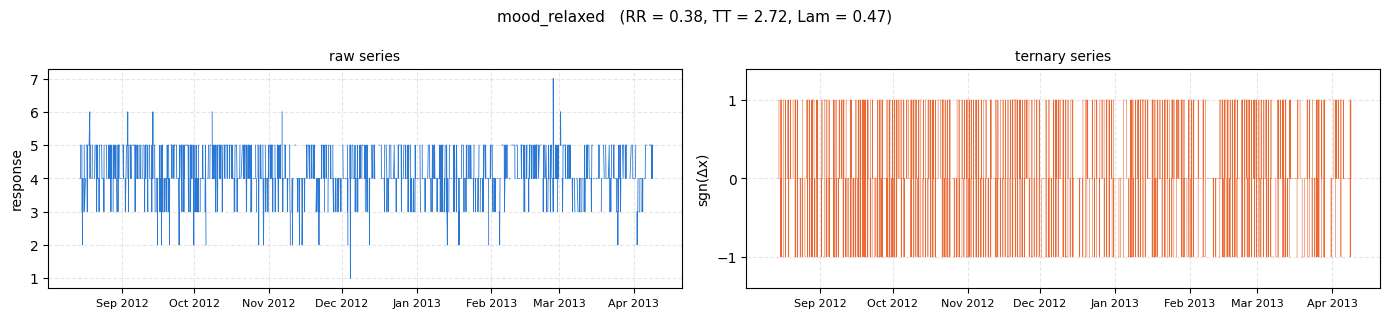

In [27]:
# ============ C.2 EMA — raw and ternary series of every item ============
# One figure per item, saved as EMA_series_images/<item>.png: raw series (left) and ternary series (right)
# over the whole period. The x axis is the date; lines are interrupted at the day breaks (night), where no
# increment is computed. The title reports RR, TT and Lam of the item (table U_ema of cell C.1).
 
def _break_lines(t, v, breaks):
    # Insert a NaN before every break, so that the line is not drawn across the night.
    t, v = np.asarray(t), np.asarray(v, float)
    idx = np.nonzero(breaks)[0]; idx = idx[idx > 0]
    t_nan = t[idx - 1] + (t[idx] - t[idx - 1]) / 2
    tt = np.insert(t, idx, t_nan); vv = np.insert(v, idx, np.nan)
    return tt, vv
 
def plot_item_series(item, outdir='EMA_series_images', show=False):
    t = ema['dt'].values
    raw = ema[item].values.astype(float)
    ter = ternarize(raw, ema_breaks)
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 3.2), sharex=True)
    tx, rx = _break_lines(t, raw, ema_breaks)
    a1.plot(tx, rx, lw=0.6, color='#2a78d6')
    a1.set_ylabel('response'); a1.set_title('raw series', fontsize=10)
    tx, sx = _break_lines(t, ter, ema_breaks)
    a2.plot(tx, sx, lw=0.4, color='#eb6834', drawstyle='steps-mid')
    a2.set_yticks([-1, 0, 1]); a2.set_ylim(-1.4, 1.4)
    a2.set_ylabel('sgn(Δx)'); a2.set_title('ternary series', fontsize=10)
    for ax in (a1, a2):
        ax.xaxis.set_major_locator(mdates.MonthLocator()); ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
        ax.tick_params(axis='x', labelsize=8); ax.grid(ls='--', alpha=.3)
    u = U_ema.loc[item]
    fig.suptitle(f'{item}   (RR = {u.RR_eff:.2f}, TT = {u.TT:.2f}, Lam = {u.Lam:.2f})', fontsize=11)
    fig.tight_layout()
    os.makedirs(outdir, exist_ok=True)
    path = os.path.join(outdir, f'{item}.png')
    fig.savefig(path, dpi=200, bbox_inches='tight')
    plt.show() if show else plt.close(fig)
    return path
 
if 'ema' in globals() and 'U_ema' in globals():
    paths = [plot_item_series(c) for c in ITEMS]
    print(f'{len(paths)} figures saved in {os.path.abspath("EMA_series_images")}')
    plot_item_series(ITEMS[0], show=True)          # preview of the first item

 

In [29]:
# ============ C.3 SMEAR, 30-minute data (summer 2025) ============
# Preprocessing (fixed before looking at the results):
#   - regular 30-minute grid; missing values stay NaN and become breaks;
#   - the mean diurnal cycle is removed: for every half-hour slot of the day, the mean over a centered
#     31-day window is subtracted (this removes the day/night cycle shared by all variables, which would
#     act as a common driver, while following its slow change during the summer);
#   - daytime only (06:00-17:30, 24 samples per day), with a break at the start of every day:
#     at night GPP is set to 0 and has no dynamics; no increments or runs across the night.
SMEAR30_FILE = 'New_30minDataset_SMEAR.csv'
VARS30 = ['HYY_EDDY233.GPP', 'HYY_RAD.PAR', 'HYY_META.Tst270', 'HYY_META.RHTd']
DAY_START, DAY_END = 6, 18          # hours kept: [6, 18)
WIN_DAYS = 31                       # window (days) for the mean diurnal cycle

if os.path.exists(SMEAR30_FILE):
    s30 = pd.read_csv(SMEAR30_FILE, sep=None, engine='python')
    s30['datetime'] = pd.to_datetime(s30['datetime'])
    X30 = s30.set_index('datetime')[VARS30].astype(float).asfreq('30min')
    # mean diurnal cycle: matrix days x half-hour slots, rolling mean over days
    day = X30.index.normalize(); slot = X30.index.hour * 2 + X30.index.minute // 30
    anom30 = X30.copy()
    for v in VARS30:
        M = X30[v].groupby([day, slot]).mean().unstack()             # rows: days, columns: 48 slots
        clim = M.rolling(WIN_DAYS, center=True, min_periods=10).mean()
        row = clim.index.get_indexer(day)                            # row of every sample in the matrix
        anom30[v] = X30[v].values - clim.values[row, np.asarray(slot)]
    G30 = anom30[(anom30.index.hour >= DAY_START) & (anom30.index.hour < DAY_END)]
    d30 = G30.index.normalize()
    smear30_breaks = (d30 != np.roll(d30, 1)) | G30.isna().any(axis=1).values
    smear30_breaks[0] = True
    print(f'{len(G30)} daytime samples over {d30.nunique()} days')
    t0 = time.time()
    R_s30, U_s30 = symver(G30, breaks=smear30_breaks, max_lag=6, B=500, block=24, seed=1)
    print(f'done in {time.time() - t0:.0f} s')
    print('\nOutcome counts:'); print(R_s30.category.value_counts().to_string())
    display(U_s30.round(3))
    display(show(R_s30))
    R_s30.to_csv('SMEAR30_symver_results.csv', index=False)
else:
    print(f'{SMEAR30_FILE} not found: skipping.')

3672 daytime samples over 153 days
done in 149 s

Outcome counts:
category
synchronous slow-fast    3
driver -> response       2
no coupling              1


,TT,Lam,RR_eff
HYY_EDDY233.GPP,2.164,0.644,0.05
HYY_RAD.PAR,2.283,0.733,0.05
HYY_META.Tst270,3.209,0.825,0.05
HYY_META.RHTd,2.885,0.850,0.05


,A,B,tau,test,p_coupling,q_coupling,TT_A,TT_B,Lam_A,Lam_B,p_TT,p_Lam,q_hierarchy,outcome
0,HYY_EDDY233.GPP,HYY_RAD.PAR,0,synchrony,0.0003,0.0003,2.1641,2.2831,0.6441,0.7328,0.002,0.002,0.002,"HYY_RAD.PAR slow <-> HYY_EDDY233.GPP fast, syn..."
1,HYY_EDDY233.GPP,HYY_META.Tst270,0,synchrony,0.0003,0.0003,2.1641,3.2091,0.6441,0.8252,0.002,0.002,0.002,"HYY_META.Tst270 slow <-> HYY_EDDY233.GPP fast,..."
2,HYY_EDDY233.GPP,HYY_META.RHTd,-1,lag,0.0003,0.0003,2.1641,2.8846,0.6441,0.8498,0.002,0.002,0.002,HYY_META.RHTd -> HYY_EDDY233.GPP (driver -> re...
3,HYY_RAD.PAR,HYY_META.Tst270,0,synchrony,0.0003,0.0003,2.2831,3.2091,0.7328,0.8252,0.002,0.002,0.002,"HYY_META.Tst270 slow <-> HYY_RAD.PAR fast, syn..."
4,HYY_RAD.PAR,HYY_META.RHTd,-1,lag,0.0003,0.0003,2.2831,2.8846,0.7328,0.8498,0.002,0.002,0.002,HYY_META.RHTd -> HYY_RAD.PAR (driver -> respon...
5,HYY_META.Tst270,HYY_META.RHTd,-5,lag,0.9005,0.9005,3.2091,2.8846,0.8252,0.8498,1.000,0.006,NaN,no coupling


# Part D — Hysteresis plots of the identified pairs

For every pair classified as **driver → response**, the response at time t + lag is plotted against the driver at time t, separately for moments in which the driver is increasing (red) and decreasing (blue). Lines are medians per driver value (per bin for continuous data); numbers are counts; bins with fewer than 5 points are not drawn. Pairs (t, t + lag) that cross a break (night in EMA, gap or change of year in SMEAR) are excluded.

Reading: separated red and blue curves = the response depends on the direction of the driver (hysteresis); overlapping curves = no hysteresis. The plot is descriptive and has no significance test attached.

Set `INCLUDE_SYNC = True` to also plot the *synchronous slow-fast* pairs (lag 0, slow variable on the x axis). Figures are saved as PNG in the notebook folder.


In [30]:
# ============ D.0 Settings ============
INCLUDE_SYNC = False   # True: also plot the 'synchronous slow-fast' pairs (lag 0)


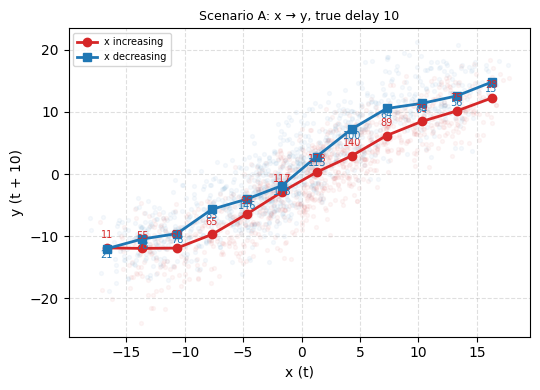

In [31]:
# ============ D.1 Reference: hysteresis in a synthetic system with known driver (scenario A, realization 0) ============
if 'DATA' in globals():
    ref = DATA[('A_delay_in_phase', 0)]
    fig, ax = plt.subplots(figsize=(5.5, 4))
    plot_hysteresis(ref, 'x', 'y', LAG, ax=ax, num_bins=12)
    ax.set_title(f'Scenario A: x → y, true delay {LAG}', fontsize=9); plt.tight_layout(); plt.show()
else:
    print('Run Part B first to see the synthetic reference.')


28 images saved in /Users/iacopocaporossi/Desktop/Dottorato/SymVeR/EMA_hysteresis_images


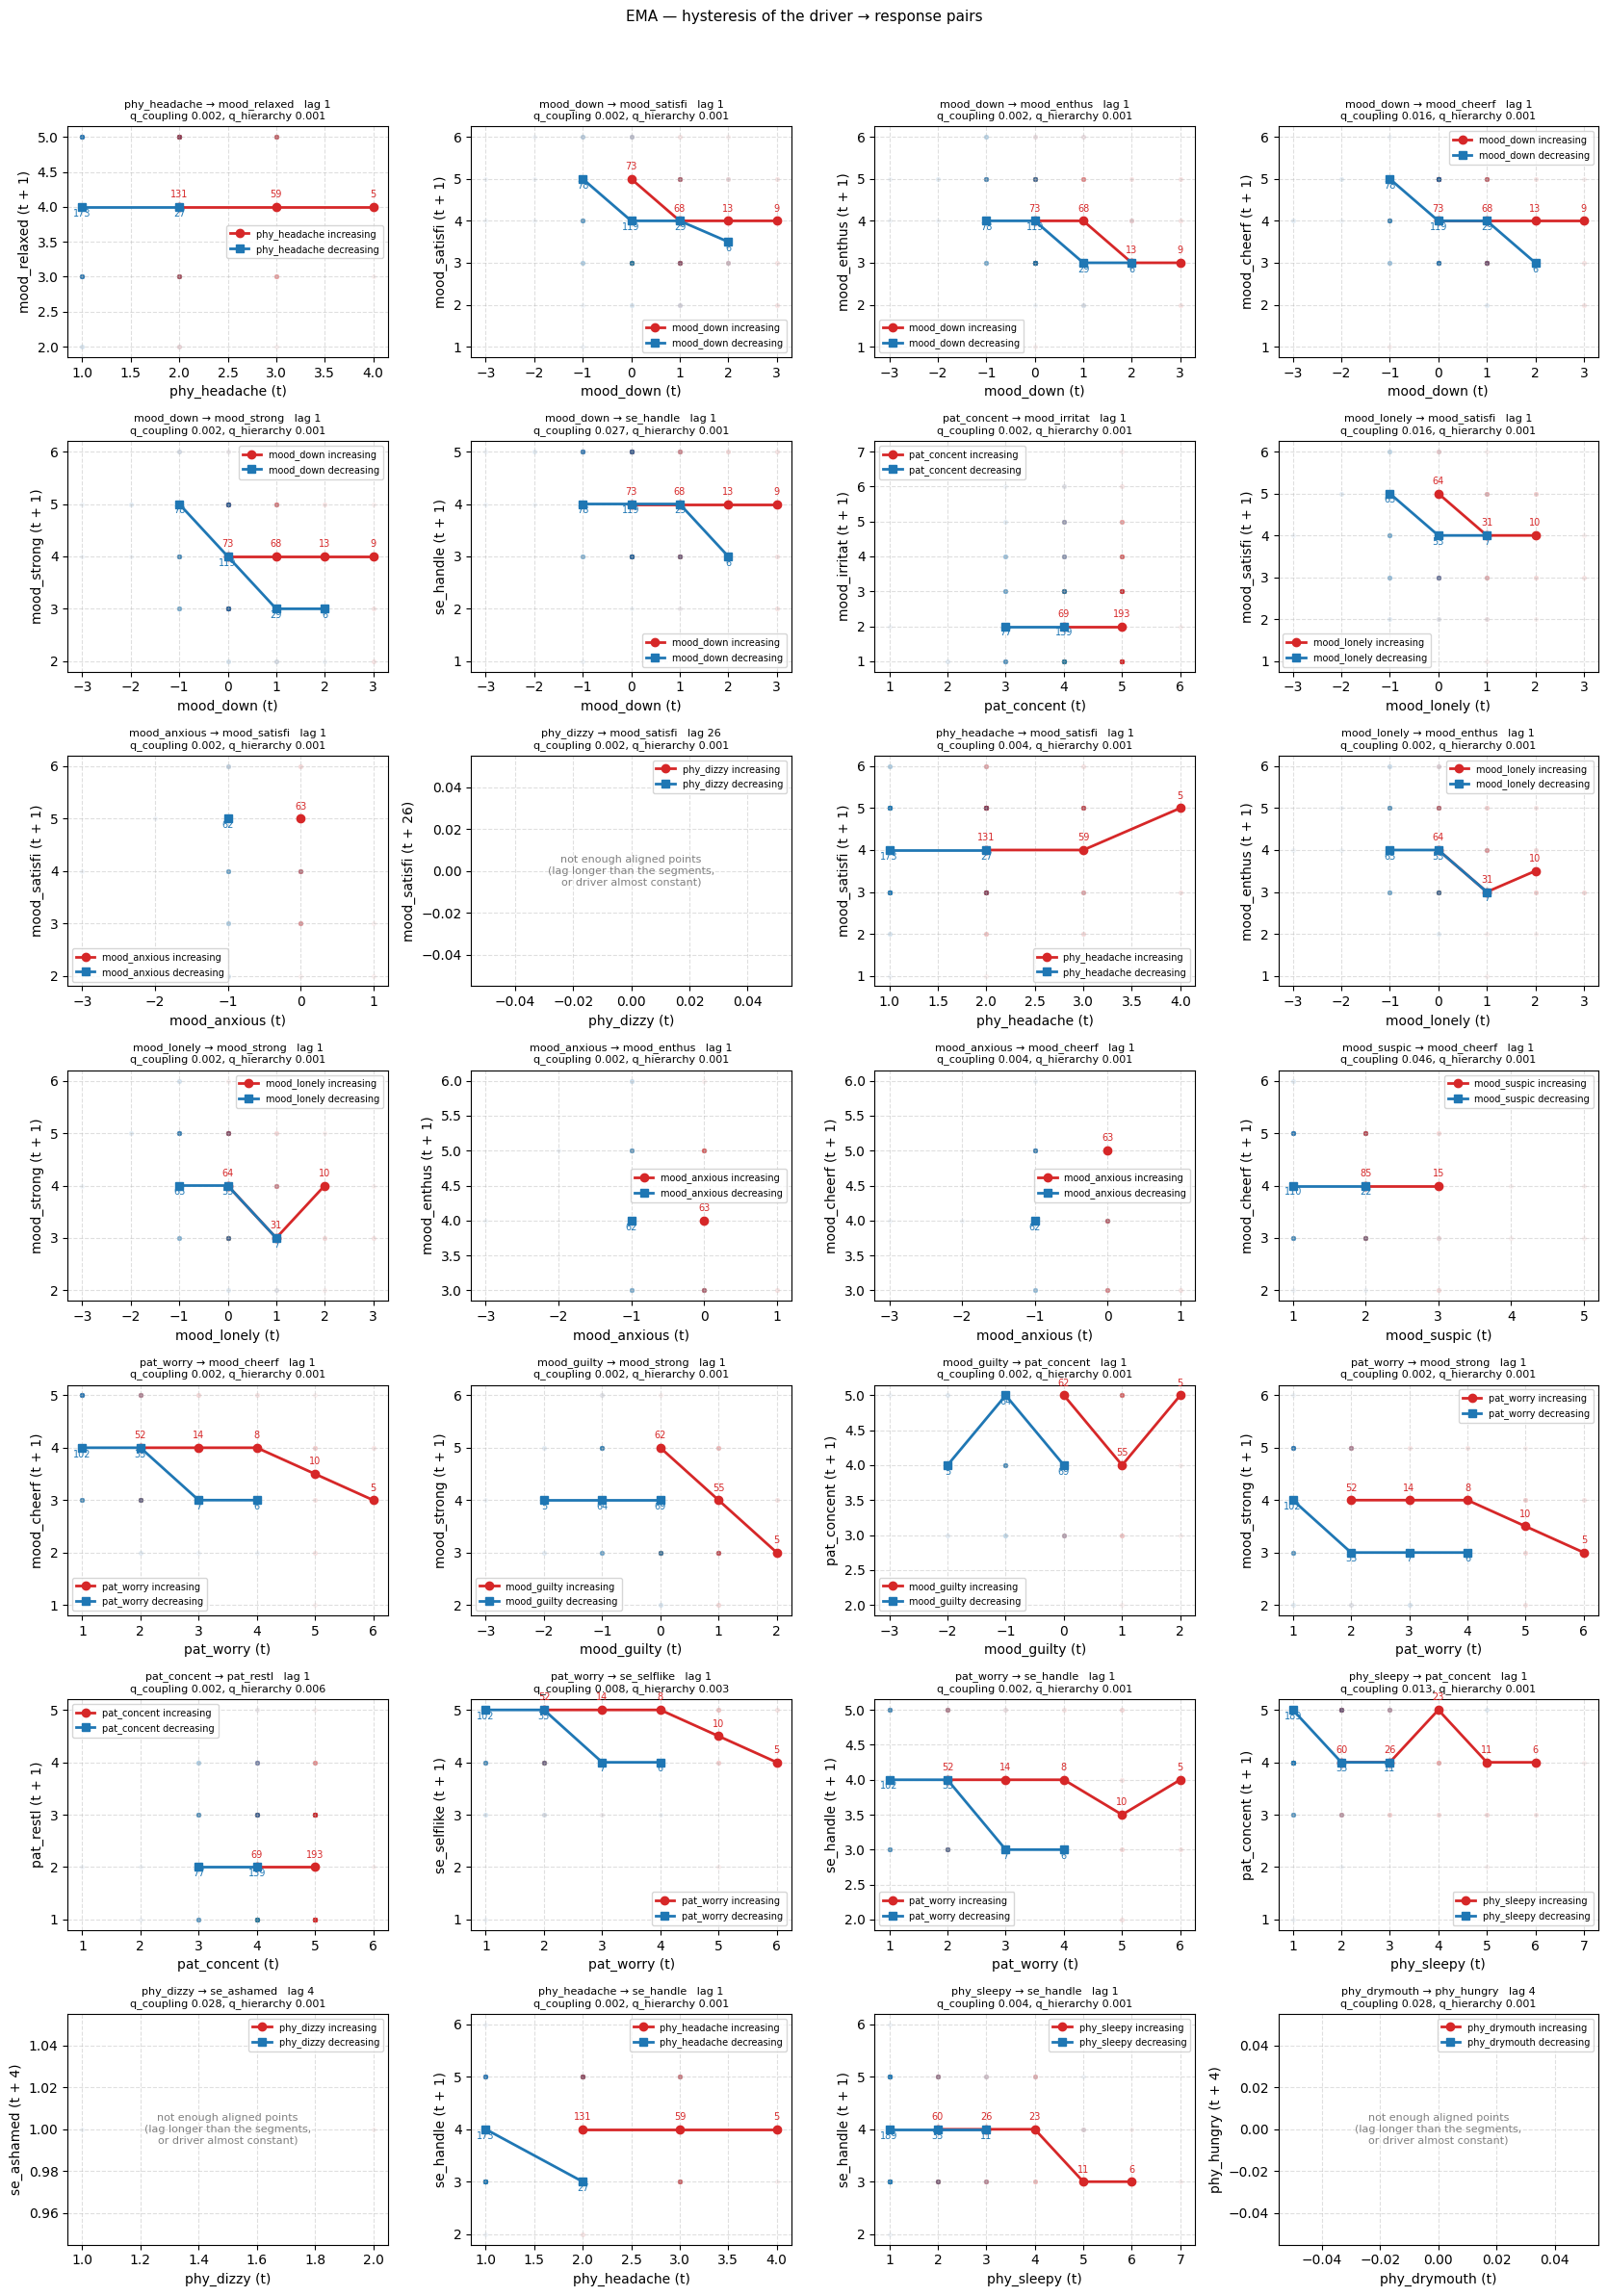

,driver,response,lag,category,q_coupling,q_hierarchy,file
0,phy_headache,mood_relaxed,1,driver -> response,0.001999,0.001459,EMA_hysteresis_images/mood_relaxed_vs_phy_head...
1,mood_down,mood_satisfi,1,driver -> response,0.001999,0.001459,EMA_hysteresis_images/mood_satisfi_vs_mood_dow...
2,mood_down,mood_enthus,1,driver -> response,0.001999,0.001459,EMA_hysteresis_images/mood_enthus_vs_mood_down...
3,mood_down,mood_cheerf,1,driver -> response,0.016039,0.001459,EMA_hysteresis_images/mood_cheerf_vs_mood_down...
4,mood_down,mood_strong,1,driver -> response,0.001999,0.001459,EMA_hysteresis_images/mood_strong_vs_mood_down...
5,mood_down,se_handle,1,driver -> response,0.027464,0.001459,EMA_hysteresis_images/se_handle_vs_mood_down.png
6,pat_concent,mood_irritat,1,driver -> response,0.001999,0.001459,EMA_hysteresis_images/mood_irritat_vs_pat_conc...
7,mood_lonely,mood_satisfi,1,driver -> response,0.016039,0.001459,EMA_hysteresis_images/mood_satisfi_vs_mood_lon...
8,mood_anxious,mood_satisfi,1,driver -> response,0.001999,0.001459,EMA_hysteresis_images/mood_satisfi_vs_mood_anx...
9,phy_dizzy,mood_satisfi,26,driver -> response,0.001999,0.001459,EMA_hysteresis_images/mood_satisfi_vs_phy_dizz...


In [32]:
# ============ D.2 EMA ============
# One image per driver -> response pair, saved as EMA_hysteresis_images/<response>_vs_<driver>.png
# (the folder is created inside the working folder). The grid below is only for viewing and is not saved.
if 'R_ema' in globals():
    P_ema = save_hysteresis_images(ema[ITEMS], R_ema, 'EMA_hysteresis_images', breaks=ema_breaks,
                                   num_bins=None, include_sync=INCLUDE_SYNC)
    plot_all_hysteresis(ema[ITEMS], R_ema, breaks=ema_breaks, num_bins=None, include_sync=INCLUDE_SYNC,
                        title='EMA — hysteresis of the driver → response pairs')
    display(P_ema)
else:
    print('Run cell C.1 first.')

In [ ]:
'''# ============ D.2 EMA ============
if 'R_ema' in globals():
    P_ema = plot_all_hysteresis(ema[ITEMS], R_ema, breaks=ema_breaks, num_bins=None, include_sync=INCLUDE_SYNC,
                                title='EMA — hysteresis of the driver → response pairs', fname='EMA_hysteresis.png')
    display(P_ema)
else:
    print('Run cell C.1 first.')
'''

In [33]:
# ============ D.3 SMEAR ============
if 'R_smear' in globals():
    P_smear = plot_all_hysteresis(G, R_smear, breaks=smear_breaks, num_bins=8, include_sync=INCLUDE_SYNC,
                                  title='SMEAR (anomalies, May-September) — hysteresis of the driver → response pairs',
                                  fname='SMEAR_hysteresis.png')
    display(P_smear)
else:
    print('Run cell C.2 first.')


Run cell C.2 first.


5 images saved in /Users/iacopocaporossi/Desktop/Dottorato/SymVeR/SMEAR30_hysteresis_images


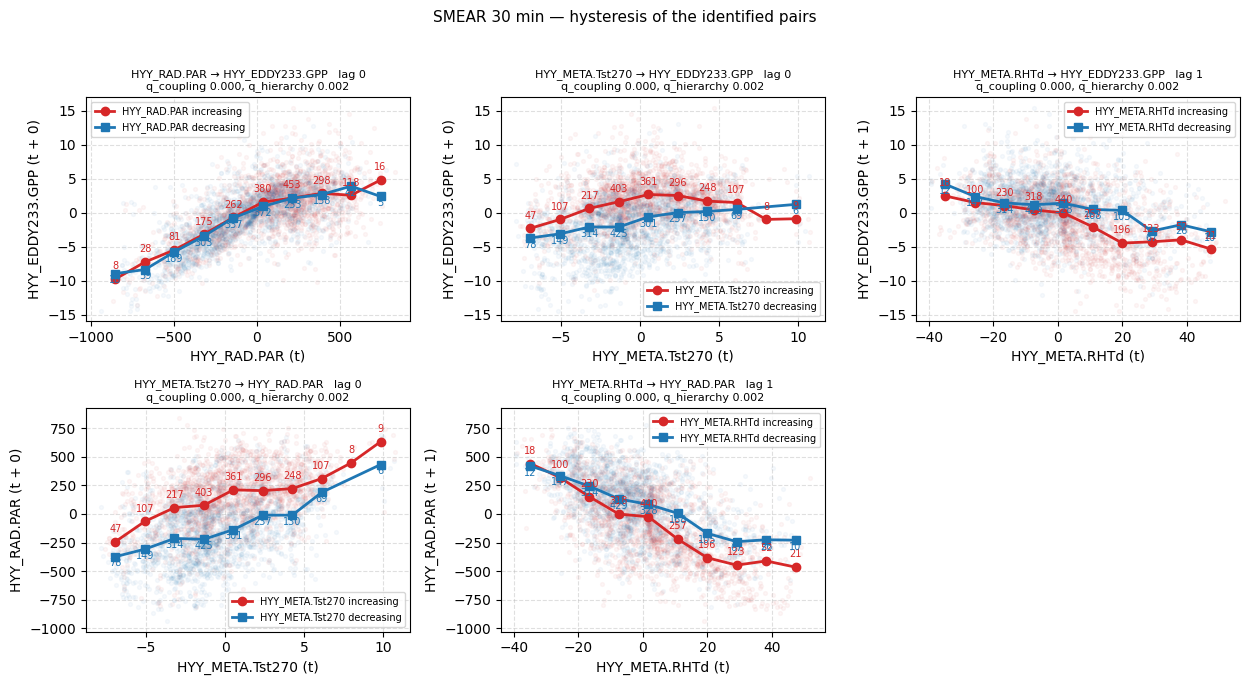

,driver,response,lag,category,q_coupling,q_hierarchy,file
0,HYY_RAD.PAR,HYY_EDDY233.GPP,0,synchronous slow-fast,0.000329,0.001996,SMEAR30_hysteresis_images/HYY_EDDY233.GPP_vs_H...
1,HYY_META.Tst270,HYY_EDDY233.GPP,0,synchronous slow-fast,0.000329,0.001996,SMEAR30_hysteresis_images/HYY_EDDY233.GPP_vs_H...
2,HYY_META.RHTd,HYY_EDDY233.GPP,1,driver -> response,0.000329,0.001996,SMEAR30_hysteresis_images/HYY_EDDY233.GPP_vs_H...
3,HYY_META.Tst270,HYY_RAD.PAR,0,synchronous slow-fast,0.000329,0.001996,SMEAR30_hysteresis_images/HYY_RAD.PAR_vs_HYY_M...
4,HYY_META.RHTd,HYY_RAD.PAR,1,driver -> response,0.000329,0.001996,SMEAR30_hysteresis_images/HYY_RAD.PAR_vs_HYY_M...


In [34]:
# ============ D.4 SMEAR, 30-minute data ============
# One image per pair, saved as SMEAR30_hysteresis_images/<response>_vs_<driver>.png.
# include_sync=True: the synchronous slow-fast pairs (lag 0, slow variable on the x axis) are plotted too,
# because in these data they are the main result. The variables are deviations from the mean diurnal cycle.
if 'R_s30' in globals():
    P_s30 = save_hysteresis_images(G30, R_s30, 'SMEAR30_hysteresis_images', breaks=smear30_breaks,
                                   num_bins=10, include_sync=True)
    plot_all_hysteresis(G30, R_s30, breaks=smear30_breaks, num_bins=10, include_sync=True, ncols=3,
                        title='SMEAR 30 min — hysteresis of the identified pairs')
    display(P_s30)
else:
    print('Run cell C.3 first.')

# metti solo le imagini di GPP domanda fisiologica 

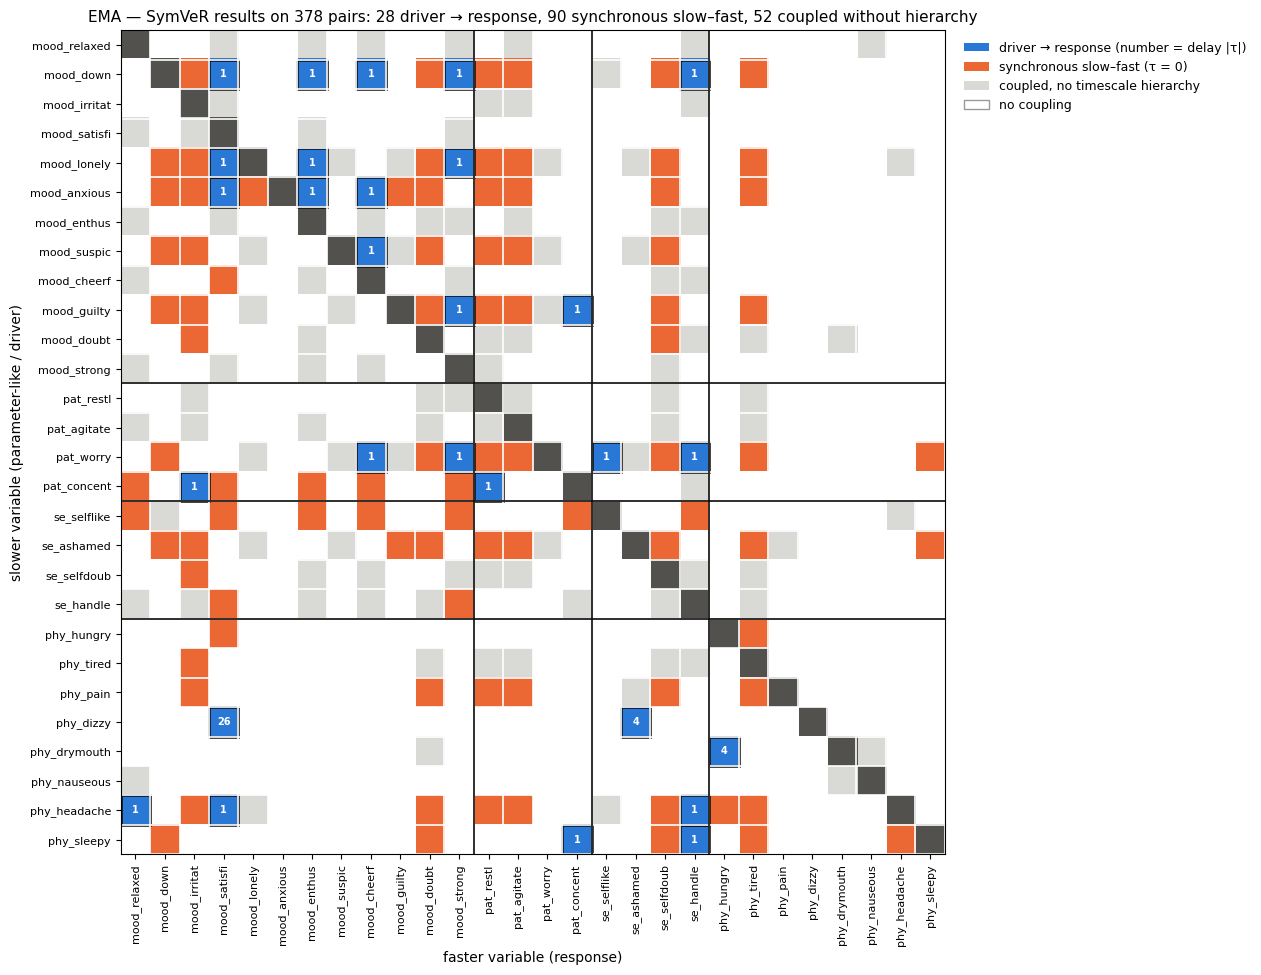

28 pairs framed (include_sync = False); figure saved as EMA_symver_heatmap.png


In [35]:
# ============ D.5 EMA — heat map of the SymVeR results ============
# Rows: the slower variable (parameter-like / driver). Columns: the faster variable (response).
#   blue   : driver -> response (delayed coupling); the number in the cell is the delay |tau| (in responses)
#   orange : synchronous slow-fast (tau = 0)
#   gray   : coupled, no timescale hierarchy (no direction: shown in both cells of the pair)
#   white  : no coupling
# Cells with a black frame are the pairs passed to plot_hysteresis in D.2
# (driver -> response; plus synchronous slow-fast if INCLUDE_SYNC = True).
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch, Rectangle

if 'R_ema' in globals():
    include_sync = globals().get('INCLUDE_SYNC', False)
    items = list(ITEMS)
    pos = {c: i for i, c in enumerate(items)}
    n = len(items)
    M = np.zeros((n, n))                      # 0 no coupling, 1 coupled no hierarchy, 2 synchronous, 3 driver->response
    LAG = np.full((n, n), np.nan)
    for _, r in R_ema.iterrows():
        a, b = pos[r.A], pos[r.B]
        if r.category == 'coupled, no timescale hierarchy':
            M[a, b] = M[b, a] = 1
        elif r.category in ('synchronous slow-fast', 'driver -> response'):
            slow = r.slow_candidate; fast = r.B if slow == r.A else r.A
            i, j = pos[slow], pos[fast]
            M[i, j] = 3 if r.category == 'driver -> response' else 2
            if r.category == 'driver -> response':
                LAG[i, j] = abs(r.tau)
    np.fill_diagonal(M, np.nan)

    cmap = ListedColormap(['#ffffff', '#d9d9d6', '#eb6834', '#2a78d6'])
    cmap.set_bad('#52514e')                   # diagonal
    fig, ax = plt.subplots(figsize=(11.5, 10))
    ax.imshow(np.ma.masked_invalid(M), cmap=cmap, vmin=-0.5, vmax=3.5)

    # thin white grid between cells
    ax.set_xticks(np.arange(-.5, n, 1), minor=True); ax.set_yticks(np.arange(-.5, n, 1), minor=True)
    ax.grid(which='minor', color='white', linewidth=1.2); ax.tick_params(which='minor', length=0)

    # separators between item groups (mood_, pat_, se_, phy_)
    groups = [c.split('_')[0] for c in items]
    for k in range(1, n):
        if groups[k] != groups[k - 1]:
            ax.axhline(k - .5, color='#0b0b0b', lw=1.2); ax.axvline(k - .5, color='#0b0b0b', lw=1.2)

    # delays and frames for the pairs sent to plot_hysteresis
    P = hysteresis_pairs(R_ema, include_sync)
    for _, p in P.iterrows():
        i, j = pos[p.driver], pos[p.response]
        ax.add_patch(Rectangle((j - .5, i - .5), 1, 1, fill=False, edgecolor='#0b0b0b', lw=1.8))
        if p.category == 'driver -> response':
            ax.text(j, i, str(int(p.lag)), ha='center', va='center', fontsize=7, color='white', fontweight='bold')

    ax.set_xticks(range(n)); ax.set_xticklabels(items, rotation=90, fontsize=8)
    ax.set_yticks(range(n)); ax.set_yticklabels(items, fontsize=8)
    ax.set_xlabel('faster variable (response)', fontsize=10)
    ax.set_ylabel('slower variable (parameter-like / driver)', fontsize=10)
    counts = R_ema.category.value_counts()
    ax.set_title(f'EMA — SymVeR results on {len(R_ema)} pairs: '
                 f'{counts.get("driver -> response", 0)} driver → response, '
                 f'{counts.get("synchronous slow-fast", 0)} synchronous slow–fast, '
                 f'{counts.get("coupled, no timescale hierarchy", 0)} coupled without hierarchy', fontsize=11)
    legend = [Patch(facecolor='#2a78d6', label='driver → response (number = delay |τ|)'),
              Patch(facecolor='#eb6834', label='synchronous slow–fast (τ = 0)'),
              Patch(facecolor='#d9d9d6', label='coupled, no timescale hierarchy'),
              Patch(facecolor='#ffffff', edgecolor='#999999', label='no coupling')]
              #Patch(facecolor='none', edgecolor='#0b0b0b', lw=1.8, label='pair passed to plot_hysteresis')]
    ax.legend(handles=legend, loc='upper left', bbox_to_anchor=(1.01, 1), fontsize=9, frameon=False)
    plt.tight_layout(); plt.savefig('EMA_symver_heatmap.png', dpi=200, bbox_inches='tight'); plt.show()
    print(f'{len(P)} pairs framed (include_sync = {include_sync}); figure saved as EMA_symver_heatmap.png')
else:
    print('Run cell C.1 first.')